# Part C
## Conditional Latent Diffusion Models (With Drift Analysis and Adaptive Trajectory Correction)



## What You Will Build

| Task | Topic |
|------|-------|
| **C.1** | Train a Convolutional VAE on MNIST |
| **C.2** | Latent Space Analysis & Normalization |
| **C.3** | Class-Conditional Latent Diffusion (CFG) |
| **C.4** | Latent Drift: Understanding & Measuring It |
| **C.5** | Mitigating Drift: Adaptive Trajectory Correction |
| **C.6** | Evaluation: Does Correction Actually Help? |
| **C.7** | Analytical Questions |

---

## Background

### Why Latent Space?
Latent Diffusion Models (Rombach et al., 2022) run the diffusion process in the compressed latent space of a pretrained VAE. This reduces the spatial resolution from $28 \times 28$ to $7 \times 7$ (4× downsampling), making diffusion significantly cheaper while preserving perceptual quality.

### What is Latent Drift?
During the reverse diffusion process, the model iteratively predicts and removes noise. However, each denoising step introduces small prediction errors. These errors **accumulate** across the $T$ steps — the predicted $x_{t-1}$ drifts away from the true posterior trajectory. This is especially pronounced in:
- Long reverse chains ($T = 1000$)
- Conditional models where the conditioning signal is weak
- The early reverse steps (high $t$) where the model has the least signal

### Adaptive Correction
Drawing inspiration from ADA (Adaptive Data Augmentation, Karras et al., 2020) and Langevin dynamics, we can insert **correction steps** during sampling that push $x_t$ back toward a well-behaved region — either toward the data manifold, toward the correct class, or toward a lower-energy state under the learned score. The key design question is: *how often, and how strongly, should we correct?*

---
## Setup

In [7]:
!pip install torch torchvision matplotlib tqdm einops scikit-learn --quiet

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import math
from einops import rearrange
from torch.optim import Adam
from torch.utils.data import DataLoader
from sklearn.manifold import TSNE
import time
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

torch.manual_seed(42)
np.random.seed(42)

Device: cuda


---
# C.1 — Convolutional VAE

Your VAE maps $28 \times 28$ MNIST images to a latent of shape $(C_z, 7, 7)$ via 2× spatial downsampling at each of two encoder stages.

**Architecture requirements:**
- **Encoder:** 3 Conv layers (strides 1, 2, 2) to reach $7 \times 7$. Output separate $\mu$ and $\log \sigma^2$ heads.
- **Reparameterization:** $z = \mu + \sigma \odot \epsilon$, $\epsilon \sim \mathcal{N}(0,I)$
- **Decoder:** Transpose convolutions (or upsample + conv) from $7 \times 7$ back to $28 \times 28$. Tanh output (images in $[-1,1]$).
- **Loss:** $\mathcal{L} = \mathcal{L}_{\text{recon}} + \lambda_{\text{KL}} \cdot D_{\text{KL}}$
  - $\mathcal{L}_{\text{recon}} = \text{MSE}(x, \hat{x})$
  - $D_{\text{KL}} = -\frac{1}{2}\sum_j(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2)$

**Deliverables after training:**
1. Training loss curve (total, recon, KL on separate axes).
2. 8 original/reconstruction side-by-side pairs.
3. t-SNE of $\mu$ vectors from 1000 test images, colored by digit class.

In [9]:
# Data — normalize to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2 - 1)
])

train_dataset = datasets.MNIST('./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST('./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True,  num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False, num_workers=0, pin_memory=True)

In [10]:
LATENT_CH = 4  # C_z — you may change this; document your choice

class Encoder(nn.Module):
    """
    TODO: Convolutional encoder.
    Input:  (B, 1, 28, 28)
    Output: mu (B, LATENT_CH, 7, 7), log_var (B, LATENT_CH, 7, 7)

    Suggested channel progression: 1 -> 32 -> 64 -> LATENT_CH*2
    Use strides [1, 2, 2] to go 28 -> 28 -> 14 -> 7.
    Split the final output into mu and log_var along the channel dim.
    """
    def __init__(self, latent_ch=LATENT_CH):
        super().__init__()
        # YOUR CODE HERE
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=1, padding=1),
            nn.SiLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.SiLU(),
            nn.Conv2d(64, latent_ch * 2, 3, stride=2, padding=1)
        )

    def forward(self, x):
        # YOUR CODE HERE
        h = self.net(x)
        mu, log_var = torch.chunk(h, 2, dim=1)
        return mu, log_var


class Decoder(nn.Module):
    """
    TODO: Convolutional decoder.
    Input:  (B, LATENT_CH, 7, 7)
    Output: (B, 1, 28, 28)  — use Tanh for [-1,1] range

    Mirror the encoder: upsample 7 -> 14 -> 28.
    You may use ConvTranspose2d or nn.Upsample + Conv2d.
    """
    def __init__(self, latent_ch=LATENT_CH):
        super().__init__()
        # YOUR CODE HERE
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_ch, 64, 4, stride=2, padding=1),
            nn.SiLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.SiLU(),
            nn.Conv2d(32, 1, 3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, z):
        # YOUR CODE HERE
        return self.net(z)


class VAE(nn.Module):
    def __init__(self, latent_ch=LATENT_CH):
        super().__init__()
        self.encoder = Encoder(latent_ch)
        self.decoder = Decoder(latent_ch)

    def reparameterize(self, mu, log_var):
        """
        TODO: Implement the reparameterization trick.
        During inference you may want to just return mu (no noise).
        """
        # YOUR CODE HERE
        if not self.training:
            return mu
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + std * eps

    def encode(self, x):
        """Return the deterministic latent mu (used during LDM training)."""
        mu, log_var = self.encoder(x)
        return mu

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterize(mu, log_var)
        x_recon = self.decoder(z)
        return x_recon, mu, log_var


def vae_loss(x, x_recon, mu, log_var, kl_weight=1e-3):
    """
    TODO: Compute VAE loss = recon_loss + kl_weight * kl_loss.
    Return a dict: {'total': ..., 'recon': ..., 'kl': ...}
    """
    # YOUR CODE HERE
    recon = F.mse_loss(x_recon, x, reduction='mean')
    kl = -0.5 * (1 + log_var - mu.pow(2) - log_var.exp())
    kl = kl.sum(dim=(1, 2, 3)).mean()
    total = recon + kl_weight * kl
    return {'total': total, 'recon': recon, 'kl': kl}

In [11]:
# Sanity check before training
vae_test = VAE().to(device)
x_test = torch.randn(4, 1, 28, 28).to(device)
x_recon, mu, log_var = vae_test(x_test)
assert x_recon.shape == (4, 1, 28, 28), f"Decoder output shape wrong: {x_recon.shape}"
assert mu.shape == (4, LATENT_CH, 7, 7),  f"Latent shape wrong: {mu.shape}"
print("VAE shape check passed.")

VAE shape check passed.


In [12]:
# ── VAE Training ──────────────────────────────────────────────────────────────
"""
TODO: Train the VAE for at least 20 epochs.

Requirements:
  - Optimizer: Adam, lr=1e-3
  - Track total loss, recon loss, and KL loss per epoch
  - Save the best model (lowest total validation loss) as 'vae_best.pt'
"""

VAE_EPOCHS = 25
vae = VAE().to(device)
vae_optimizer = Adam(vae.parameters(), lr=1e-3)

# YOUR CODE HERE
vae_history = {
    'train_total': [], 'train_recon': [], 'train_kl': [],
    'val_total': [], 'val_recon': [], 'val_kl': []
}
best_val_loss = float('inf')
for epoch in range(VAE_EPOCHS):
    vae.train()
    train_total = 0.0
    train_recon = 0.0
    train_kl = 0.0
    n_train = 0
    for x, _ in tqdm(train_loader, desc=f'VAE Epoch {epoch+1}/{VAE_EPOCHS}'):
        x = x.to(device, non_blocking=True)
        x_recon, mu, log_var = vae(x)
        losses = vae_loss(x, x_recon, mu, log_var, kl_weight=1e-3)
        vae_optimizer.zero_grad(set_to_none=True)
        losses['total'].backward()
        vae_optimizer.step()
        bs = x.size(0)
        train_total += losses['total'].item() * bs
        train_recon += losses['recon'].item() * bs
        train_kl += losses['kl'].item() * bs
        n_train += bs
    vae.eval()
    val_total = 0.0
    val_recon = 0.0
    val_kl = 0.0
    n_val = 0
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device, non_blocking=True)
            x_recon, mu, log_var = vae(x)
            losses = vae_loss(x, x_recon, mu, log_var, kl_weight=1e-3)
            bs = x.size(0)
            val_total += losses['total'].item() * bs
            val_recon += losses['recon'].item() * bs
            val_kl += losses['kl'].item() * bs
            n_val += bs
    train_total /= n_train
    train_recon /= n_train
    train_kl /= n_train
    val_total /= n_val
    val_recon /= n_val
    val_kl /= n_val
    vae_history['train_total'].append(train_total)
    vae_history['train_recon'].append(train_recon)
    vae_history['train_kl'].append(train_kl)
    vae_history['val_total'].append(val_total)
    vae_history['val_recon'].append(val_recon)
    vae_history['val_kl'].append(val_kl)
    if val_total < best_val_loss:
        best_val_loss = val_total
        torch.save(vae.state_dict(), 'vae_best.pt')
    print(f"epoch {epoch+1:02d} | train total {train_total:.6f} recon {train_recon:.6f} kl {train_kl:.6f} | val total {val_total:.6f} recon {val_recon:.6f} kl {val_kl:.6f}")
vae.load_state_dict(torch.load('vae_best.pt', map_location=device))
vae.eval()
print("loaded best VAE from vae_best.pt")

VAE Epoch 1/25:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 01 | train total 0.217122 recon 0.155002 kl 62.120510 | val total 0.097578 recon 0.022159 kl 75.419425


VAE Epoch 2/25:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 02 | train total 0.120785 recon 0.049438 kl 71.347267 | val total 0.084528 recon 0.017747 kl 66.781319


VAE Epoch 3/25:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 03 | train total 0.113136 recon 0.045266 kl 67.869985 | val total 0.082085 recon 0.016171 kl 65.914758


... (40 outputs left out)

VAE Epoch 24/25:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 24 | train total 0.096449 recon 0.036328 kl 60.121567 | val total 0.074003 recon 0.014481 kl 59.522520


VAE Epoch 25/25:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 25 | train total 0.096311 recon 0.036165 kl 60.145874 | val total 0.074940 recon 0.014713 kl 60.226712
loaded best VAE from vae_best.pt


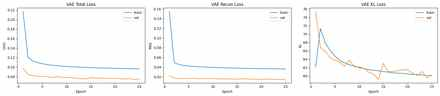

In [13]:
# ── Plot VAE training curves ───────────────────────────────────────────────────
"""
TODO: Plot total loss, recon loss, and KL loss on separate subplots.
"""
# YOUR CODE HERE
epochs = np.arange(1, VAE_EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(epochs, vae_history['train_total'], label='train')
axes[0].plot(epochs, vae_history['val_total'], label='val')
axes[0].set_title('VAE Total Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[1].plot(epochs, vae_history['train_recon'], label='train')
axes[1].plot(epochs, vae_history['val_recon'], label='val')
axes[1].set_title('VAE Recon Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE')
axes[1].legend()
axes[2].plot(epochs, vae_history['train_kl'], label='train')
axes[2].plot(epochs, vae_history['val_kl'], label='val')
axes[2].set_title('VAE KL Loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('KL')
axes[2].legend()
plt.tight_layout()
plt.show()

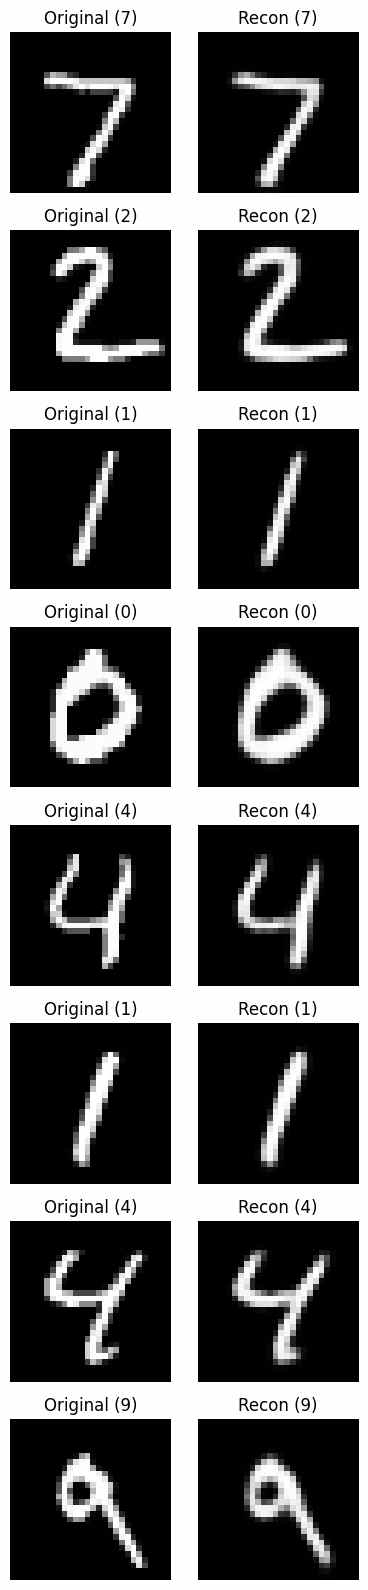

In [14]:
# ── Visualize reconstructions ─────────────────────────────────────────────────
"""
TODO: For 8 test images, show: [original | reconstruction] pairs side-by-side.
Label each pair with the digit class.
"""
# YOUR CODE HERE
vae.eval()
x_vis, y_vis = next(iter(test_loader))
x_vis = x_vis[:8].to(device)
y_vis = y_vis[:8]
with torch.no_grad():
    x_recon, _, _ = vae(x_vis)
orig = ((x_vis.clamp(-1, 1) + 1) / 2).cpu()
recon = ((x_recon.clamp(-1, 1) + 1) / 2).cpu()
fig, axes = plt.subplots(8, 2, figsize=(4, 16))
for i in range(8):
    axes[i, 0].imshow(orig[i, 0], cmap='gray')
    axes[i, 0].set_title(f'Original ({y_vis[i].item()})')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(recon[i, 0], cmap='gray')
    axes[i, 1].set_title(f'Recon ({y_vis[i].item()})')
    axes[i, 1].axis('off')
plt.tight_layout()
plt.show()

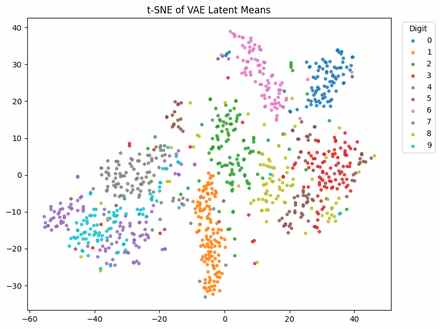

In [15]:
# ── t-SNE of latent space ─────────────────────────────────────────────────────
"""
TODO:
  1. Pass 1000 test images through vae.encode() to get mu vectors.
  2. Flatten each mu to a 1D vector (shape: 1000, LATENT_CH*7*7).
  3. Run TSNE(n_components=2) from sklearn.
  4. Scatter plot colored by digit class (use 10 distinct colors).
  5. Add a legend.
"""
# YOUR CODE HERE
vae.eval()
latent_list = []
label_list = []
count = 0
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)
        mu = vae.encode(x).cpu()
        latent_list.append(mu)
        label_list.append(y)
        count += x.size(0)
        if count >= 1000:
            break
latents = torch.cat(latent_list, dim=0)[:1000]
labels = torch.cat(label_list, dim=0)[:1000]
latents_flat = latents.flatten(1).numpy()
tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto', perplexity=30)
latents_2d = tsne.fit_transform(latents_flat)
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for digit in range(10):
    idx = labels.numpy() == digit
    ax.scatter(latents_2d[idx, 0], latents_2d[idx, 1], s=12, color=colors[digit], label=str(digit), alpha=0.8)
ax.set_title('t-SNE of VAE Latent Means')
ax.legend(title='Digit', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---
# C.2 — Latent Statistics and Normalization

Before training the diffusion model on latents, you must understand the latent distribution. Diffusion models assume data roughly in $[-1,1]$ or with unit variance — raw VAE latents often violate this.

**Your tasks:**
1. Extract all training latents $\{\mu_i\}$ from the frozen encoder.
2. Compute per-channel mean and std across the full training set.
3. Plot histograms of raw latent values per channel (one subplot per channel).
4. Define `normalize_latent(z)` and `denormalize_latent(z)` using the computed stats.
5. Plot histograms of normalized latents — verify they are approximately $\mathcal{N}(0,1)$.

In [16]:
@torch.no_grad()
def compute_latent_stats(vae, dataloader):
    """
    TODO: Compute per-channel mean and std of all training latents.

    Strategy:
      - Accumulate sum and sum-of-squares across the dataset.
      - Compute mean = sum / N, std = sqrt(sum_sq/N - mean^2).

    Returns:
        ch_mean: (LATENT_CH, 1, 1) tensor
        ch_std:  (LATENT_CH, 1, 1) tensor
    """
    # YOUR CODE HERE
    vae.eval()
    sum_ = torch.zeros(1, LATENT_CH, 1, 1, device=device)
    sum_sq = torch.zeros(1, LATENT_CH, 1, 1, device=device)
    count = 0
    for x, _ in tqdm(dataloader, desc='Computing latent stats'):
        x = x.to(device, non_blocking=True)
        mu = vae.encode(x)
        sum_ += mu.sum(dim=(0, 2, 3), keepdim=True)
        sum_sq += (mu ** 2).sum(dim=(0, 2, 3), keepdim=True)
        count += mu.shape[0] * mu.shape[2] * mu.shape[3]
    ch_mean = (sum_ / count).squeeze(0)
    ch_var = (sum_sq / count).squeeze(0) - ch_mean ** 2
    ch_std = torch.sqrt(ch_var.clamp(min=1e-6))
    return ch_mean, ch_std

latent_mean, latent_std = compute_latent_stats(vae, train_loader)
latent_mean = latent_mean.to(device)
latent_std  = latent_std.to(device)
print(f"Per-channel mean: {latent_mean.squeeze().cpu().numpy()}")
print(f"Per-channel std:  {latent_std.squeeze().cpu().numpy()}")


def normalize_latent(z):
    """TODO: Normalize z to approximately N(0,1) per channel."""
    # YOUR CODE HERE
    return (z - latent_mean) / latent_std

def denormalize_latent(z_norm):
    """TODO: Inverse of normalize_latent."""
    # YOUR CODE HERE
    return z_norm * latent_std + latent_mean

Computing latent stats:   0%|          | 0/235 [00:00<?, ?it/s]

Per-channel mean: [0.00902444 0.00221895 0.00673377 0.00261152]
Per-channel std:  [0.8285769  0.02125269 0.4486562  0.519964  ]


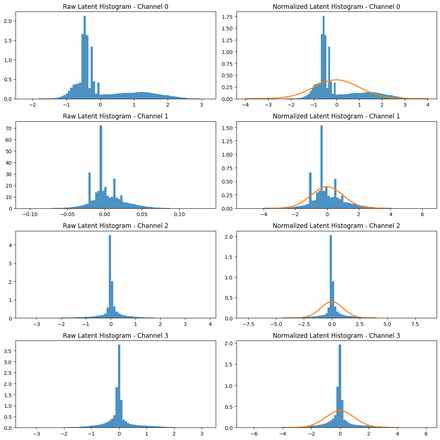

In [17]:
# ── Plot raw vs. normalized histograms ────────────────────────────────────────
"""
TODO: For each latent channel, plot:
  Left subplot:  histogram of raw latent values
  Right subplot: histogram of normalized latent values
Overlay a standard N(0,1) curve on the normalized histograms.
"""
# YOUR CODE HERE
vae.eval()
raw_latents = []
with torch.no_grad():
    for x, _ in tqdm(train_loader, desc='Collecting latents for histograms'):
        x = x.to(device, non_blocking=True)
        mu = vae.encode(x).cpu()
        raw_latents.append(mu)
raw_latents = torch.cat(raw_latents, dim=0)
latent_mean_cpu = latent_mean.detach().cpu()
latent_std_cpu = latent_std.detach().cpu()
norm_latents = (raw_latents - latent_mean_cpu.unsqueeze(0)) / latent_std_cpu.unsqueeze(0)
fig, axes = plt.subplots(LATENT_CH, 2, figsize=(12, 3 * LATENT_CH))
if LATENT_CH == 1:
    axes = np.array([axes])
x_curve = np.linspace(-4, 4, 400)
gauss = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x_curve ** 2)
for c in range(LATENT_CH):
    raw_vals = raw_latents[:, c].reshape(-1).numpy()
    norm_vals = norm_latents[:, c].reshape(-1).numpy()
    axes[c, 0].hist(raw_vals, bins=80, density=True, alpha=0.8)
    axes[c, 0].set_title(f'Raw Latent Histogram - Channel {c}')
    axes[c, 1].hist(norm_vals, bins=80, density=True, alpha=0.8)
    axes[c, 1].plot(x_curve, gauss, linewidth=2)
    axes[c, 1].set_title(f'Normalized Latent Histogram - Channel {c}')
plt.tight_layout()
plt.show()

---
# C.3 — Class-Conditional Latent Diffusion Model

## Noise Schedule

Use the **cosine schedule** (Nichol & Dhariwal, 2021):
$$\bar{\alpha}_t = \frac{f(t)}{f(0)}, \quad f(t) = \cos\!\left(\frac{t/T + s}{1+s} \cdot \frac{\pi}{2}\right)^2, \quad s = 0.008$$
with $\beta_t = \text{clip}(1 - \bar{\alpha}_t/\bar{\alpha}_{t-1},\ 0,\ 0.999)$.

## Conditional U-Net Architecture

Your denoiser takes `(z_t, t, c)` and outputs predicted noise $\hat{\epsilon}$.

**Required components:**
1. **Sinusoidal timestep embedding** → projected through 2 linear layers (dim: `time_emb_dim`).
2. **Class embedding** via `nn.Embedding(num_classes + 1, class_emb_dim)` — index `num_classes` is the **null class** used for unconditional training.
3. **Combined conditioning:** concatenate or add time and class embeddings, then inject into each ResBlock.
4. **ResBlocks** with GroupNorm, SiLU, and conditioning injection.
5. **Self-attention** at the bottleneck.

## Classifier-Free Guidance (CFG)

During **training**, randomly drop the class label with probability $p_{\text{uncond}} = 0.15$, replacing it with the null class index. This trains the model to handle both conditional and unconditional inputs with a single network.

During **sampling**:
$$\hat{\epsilon} = \epsilon_\theta(z_t, t, \emptyset) + w \cdot \bigl(\epsilon_\theta(z_t, t, c) - \epsilon_\theta(z_t, t, \emptyset)\bigr)$$
where $w$ is the **guidance scale** and $\emptyset$ is the null class.

In [18]:
# ── Cosine noise schedule ──────────────────────────────────────────────────────
T = 1000

def cosine_beta_schedule(T, s=0.008):
    """
    TODO: Implement the cosine beta schedule.
    Returns a dict with keys:
      'betas', 'alphas', 'alpha_hats',
      'sqrt_alpha_hat', 'sqrt_one_minus_alpha_hat',
      'sqrt_recip_alpha', 'posterior_variance'
    All tensors of shape (T,) on CPU.
    """
    # YOUR CODE HERE
    steps = torch.linspace(0, T, T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T) + s) / (1 + s) * math.pi / 2) ** 2
    alpha_hats_full = f / f[0]
    betas = 1 - (alpha_hats_full[1:] / alpha_hats_full[:-1])
    betas = betas.clamp(1e-8, 0.999).float()
    alphas = (1 - betas).float()
    alpha_hats = torch.cumprod(alphas, dim=0)
    alpha_hats_prev = torch.cat([torch.ones(1), alpha_hats[:-1]], dim=0)
    sqrt_alpha_hat = torch.sqrt(alpha_hats)
    sqrt_one_minus_alpha_hat = torch.sqrt(1 - alpha_hats)
    sqrt_recip_alpha = torch.sqrt(1 / alphas)
    posterior_variance = betas * (1 - alpha_hats_prev) / (1 - alpha_hats)
    posterior_variance = posterior_variance.clamp(min=1e-20)
    return {
        'betas': betas,
        'alphas': alphas,
        'alpha_hats': alpha_hats,
        'sqrt_alpha_hat': sqrt_alpha_hat,
        'sqrt_one_minus_alpha_hat': sqrt_one_minus_alpha_hat,
        'sqrt_recip_alpha': sqrt_recip_alpha,
        'posterior_variance': posterior_variance
    }

schedule = cosine_beta_schedule(T)
# Move all schedule tensors to device for later use
sched = {k: v.to(device) for k, v in schedule.items()}


def extract(a, t, x_shape):
    """Gather values from schedule tensor `a` at timesteps `t`, broadcast to x_shape."""
    out = a.gather(-1, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))


def q_sample(x_0, t, noise=None):
    """
    TODO: Forward diffusion — add noise to x_0 at timestep t.
    Returns (x_t, noise).
    """
    # YOUR CODE HERE
    if noise is None:
        noise = torch.randn_like(x_0)
    x_t = extract(sched['sqrt_alpha_hat'], t, x_0.shape) * x_0 + extract(sched['sqrt_one_minus_alpha_hat'], t, x_0.shape) * noise
    return x_t, noise

In [19]:
# ── Building blocks ────────────────────────────────────────────────────────────

class SinusoidalEmbedding(nn.Module):
    """
    TODO: Sinusoidal timestep embedding followed by a 2-layer MLP.

    PE(t, 2i)   = sin(t / 10000^(2i/d))
    PE(t, 2i+1) = cos(t / 10000^(2i/d))

    Then: Linear(d, 4d) -> GELU -> Linear(4d, out_dim)
    """
    def __init__(self, dim, out_dim):
        super().__init__()
        # YOUR CODE HERE
        self.dim = dim
        self.mlp = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, out_dim)
        )

    def forward(self, t):
        # t: (B,) integer timesteps
        # YOUR CODE HERE
        t = t.float()
        half = self.dim // 2
        freq_denom = max(half - 1, 1)
        freqs = torch.exp(torch.arange(half, device=t.device, dtype=torch.float32) * (-math.log(10000.0) / freq_denom))
        args = t[:, None] * freqs[None, :]
        emb = torch.cat([torch.sin(args), torch.cos(args)], dim=-1)
        if self.dim % 2 == 1:
            emb = F.pad(emb, (0, 1))
        return self.mlp(emb)


class ResBlock(nn.Module):
    """
    TODO: Residual block with conditioning injection.

    Structure:
      GroupNorm -> SiLU -> Conv2d
      (add projected cond_emb here)
      GroupNorm -> SiLU -> Conv2d
      + residual projection if in_ch != out_ch

    cond_dim: dimensionality of the combined (time + class) embedding.
    """
    def __init__(self, in_ch, out_ch, cond_dim, groups=4):
        super().__init__()
        # YOUR CODE HERE
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.act1 = nn.SiLU()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.cond_proj = nn.Linear(cond_dim, out_ch)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.act2 = nn.SiLU()
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.residual = nn.Identity() if in_ch == out_ch else nn.Conv2d(in_ch, out_ch, 1)

    def forward(self, x, cond):
        # cond: (B, cond_dim) — add projected version to spatial features
        # YOUR CODE HERE
        h = self.conv1(self.act1(self.norm1(x)))
        h = h + self.cond_proj(cond)[:, :, None, None]
        h = self.conv2(self.act2(self.norm2(h)))
        return h + self.residual(x)


class SelfAttention2D(nn.Module):
    """
    TODO: Multi-head self-attention for 2D feature maps.
    Reshape (B, C, H, W) -> (B, H*W, C), apply attention, reshape back.
    Use pre-norm (GroupNorm before attention).
    """
    def __init__(self, dim, num_heads=4):
        super().__init__()
        # YOUR CODE HERE
        self.norm = nn.GroupNorm(4, dim)
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)

    def forward(self, x):
        # YOUR CODE HERE
        b, c, h, w = x.shape
        x_norm = self.norm(x)
        x_flat = rearrange(x_norm, 'b c h w -> b (h w) c')
        attn_out, _ = self.attn(x_flat, x_flat, x_flat, need_weights=False)
        attn_out = rearrange(attn_out, 'b (h w) c -> b c h w', h=h, w=w)
        return x + attn_out

In [20]:
NUM_CLASSES  = 10
NULL_CLASS   = NUM_CLASSES   # index 10 = unconditional
COND_DIM     = 256           # combined time + class embedding dim
class ConditionalLatentUNet(nn.Module):
    """
    TODO: Class-conditional U-Net operating on (LATENT_CH, 7, 7) latents.
    Input:  z_t (B, LATENT_CH, 7, 7), t (B,), c (B,) class labels
    Output: predicted noise (B, LATENT_CH, 7, 7)
    Suggested architecture for 7x7 latents:
      - Initial conv: LATENT_CH -> 128
      - Encoder: [128 -> 128, 128 -> 256]  (with ResBlocks, no spatial downsampling
                                             since 7x7 is already small)
      - Bottleneck: ResBlock + SelfAttention2D + ResBlock
      - Decoder: [256+256 -> 128, 128+128 -> 128]  (skip connections via concat)
      - Output conv: 128 -> LATENT_CH
    Class conditioning:
      - nn.Embedding(NUM_CLASSES + 1, class_emb_dim)  [+1 for null class]
      - Project class_emb to COND_DIM, add to time_emb
      - Pass combined embedding to every ResBlock
    Note: since 7x7 is small, you may skip downsampling in the encoder
    and rely purely on the bottleneck attention for global context.
    """
    def __init__(self, latent_ch=LATENT_CH, base_ch=128, cond_dim=COND_DIM):
        super().__init__()
        # YOUR CODE HERE
        self.time_emb = SinusoidalEmbedding(cond_dim, cond_dim)
        self.class_emb = nn.Embedding(NUM_CLASSES + 1, cond_dim)
        self.class_proj = nn.Sequential(nn.Linear(cond_dim, cond_dim), nn.SiLU(), nn.Linear(cond_dim, cond_dim))
        self.in_conv = nn.Conv2d(latent_ch, base_ch, 3, padding=1)
        self.enc1 = ResBlock(base_ch, base_ch, cond_dim)
        self.enc2 = ResBlock(base_ch, base_ch * 2, cond_dim)
        self.mid1 = ResBlock(base_ch * 2, base_ch * 2, cond_dim)
        self.attn = SelfAttention2D(base_ch * 2)
        self.mid2 = ResBlock(base_ch * 2, base_ch * 2, cond_dim)
        self.dec1 = ResBlock(base_ch * 4, base_ch, cond_dim)
        self.dec2 = ResBlock(base_ch * 2, base_ch, cond_dim)
        self.out_norm = nn.GroupNorm(8, base_ch)
        self.out_act = nn.SiLU()
        self.out_conv = nn.Conv2d(base_ch, latent_ch, 3, padding=1)
    def forward(self, z, t, c=None, return_intermediates=False):
        """
        z: (B, LATENT_CH, 7, 7)
        t: (B,) integer timesteps
        c: (B,) integer class labels, or None (treated as null class)
        """
        if c is None:
            c = torch.full((z.shape[0],), NULL_CLASS, dtype=torch.long, device=z.device)
        # YOUR CODE HERE
        cond = self.time_emb(t) + self.class_proj(self.class_emb(c))
        x = self.in_conv(z)
        h1 = self.enc1(x, cond)
        h2 = self.enc2(h1, cond)
        h_mid = self.mid1(h2, cond)
        h_mid = self.attn(h_mid)
        h_mid = self.mid2(h_mid, cond)
        h_dec1 = self.dec1(torch.cat([h_mid, h2], dim=1), cond)
        h_dec2 = self.dec2(torch.cat([h_dec1, h1], dim=1), cond)
        out = self.out_conv(self.out_act(self.out_norm(h_dec2)))
        if return_intermediates:
            return out, {'encoder': h2, 'bottleneck': h_mid, 'decoder': h_dec2}
        return out

In [21]:
# Sanity check
ldm_test = ConditionalLatentUNet().to(device)
z_test = torch.randn(4, LATENT_CH, 7, 7).to(device)
t_test = torch.randint(0, T, (4,)).to(device)
c_test = torch.randint(0, NUM_CLASSES, (4,)).to(device)
out = ldm_test(z_test, t_test, c_test)
assert out.shape == z_test.shape, f"Output shape mismatch: {out.shape}"
n_params = sum(p.numel() for p in ldm_test.parameters())
print(f"Model shape check passed. Parameters: {n_params:,}")

Model shape check passed. Parameters: 6,087,172


Pre-encoding latents:   0%|          | 0/235 [00:00<?, ?it/s]

Pre-encoding latents:   0%|          | 0/40 [00:00<?, ?it/s]

LDM Epoch 1/30:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 01 | train 0.306154 | val 0.217641


LDM Epoch 2/30:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 02 | train 0.202950 | val 0.191556


... (52 outputs left out)

LDM Epoch 29/30:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 29 | train 0.140299 | val 0.138361


LDM Epoch 30/30:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 30 | train 0.139867 | val 0.139907


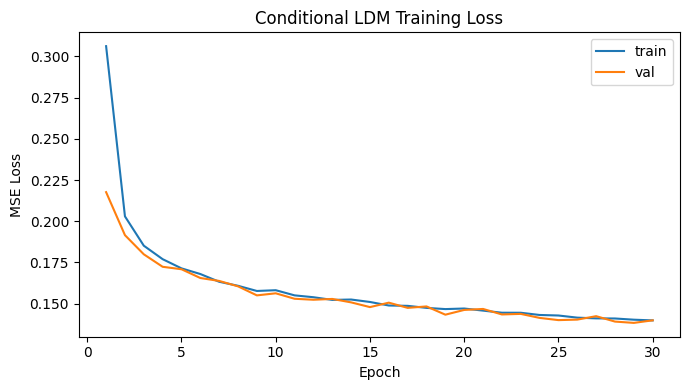

In [22]:
# ── LDM Training ──────────────────────────────────────────────────────────────
"""
TODO: Train the conditional LDM.

Training procedure:
  1. Freeze vae (no gradients through it).
  2. For each batch (x, labels):
       a. z_0 = vae.encode(x)           # deterministic latent
       b. z_0 = normalize_latent(z_0)   # normalize
       c. Sample t ~ Uniform[0, T-1]
       d. Sample eps ~ N(0, I)
       e. Compute z_t = q_sample(z_0, t, eps)
       f. With probability p_uncond=0.15, replace labels with NULL_CLASS
       g. eps_hat = model(z_t, t, labels)
       h. loss = MSE(eps, eps_hat)
  3. Optimizer: Adam, lr=2e-4
  4. Train for at least 30 epochs.
  5. Save best model as 'ldm_best.pt'.
  6. Plot training loss curve.
"""

LDM_EPOCHS  = 30
P_UNCOND    = 0.15

vae.eval()
for p in vae.parameters():
    p.requires_grad = False

ldm = ConditionalLatentUNet().to(device)
ldm_optimizer = Adam(ldm.parameters(), lr=2e-4)

# YOUR CODE HERE
from torch.utils.data import TensorDataset
@torch.no_grad()
def preencode_latents(vae, loader):
    z_all = []
    y_all = []
    for x, y in tqdm(loader, desc='Pre-encoding latents'):
        x = x.to(device, non_blocking=True)
        z = normalize_latent(vae.encode(x)).cpu()
        z_all.append(z)
        y_all.append(y.cpu())
    return TensorDataset(torch.cat(z_all, dim=0), torch.cat(y_all, dim=0))
latent_train_dataset = preencode_latents(vae, train_loader)
latent_test_dataset = preencode_latents(vae, test_loader)
latent_train_loader = DataLoader(latent_train_dataset, batch_size=256, shuffle=True, num_workers=2, pin_memory=True)
latent_test_loader = DataLoader(latent_test_dataset, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
ldm_history = {'train_loss': [], 'val_loss': []}
best_val_loss = float('inf')
for epoch in range(LDM_EPOCHS):
    ldm.train()
    train_loss = 0.0
    n_train = 0
    for z_0, labels in tqdm(latent_train_loader, desc=f'LDM Epoch {epoch+1}/{LDM_EPOCHS}'):
        z_0 = z_0.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        b = z_0.size(0)
        t = torch.randint(0, T, (b,), device=device).long()
        z_t, eps = q_sample(z_0, t)
        labels_in = labels.clone()
        drop_mask = torch.rand(b, device=device) < P_UNCOND
        labels_in[drop_mask] = NULL_CLASS
        eps_hat = ldm(z_t, t, labels_in)
        loss = F.mse_loss(eps_hat, eps)
        ldm_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(ldm.parameters(), 1.0)
        ldm_optimizer.step()
        train_loss += loss.item() * b
        n_train += b
    train_loss /= n_train
    ldm.eval()
    val_loss = 0.0
    n_val = 0
    with torch.no_grad():
        for z_0, labels in latent_test_loader:
            z_0 = z_0.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            b = z_0.size(0)
            t = torch.randint(0, T, (b,), device=device).long()
            z_t, eps = q_sample(z_0, t)
            eps_hat = ldm(z_t, t, labels)
            loss = F.mse_loss(eps_hat, eps)
            val_loss += loss.item() * b
            n_val += b
    val_loss /= n_val
    ldm_history['train_loss'].append(train_loss)
    ldm_history['val_loss'].append(val_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(ldm.state_dict(), 'ldm_best.pt')
    print(f"epoch {epoch+1:02d} | train {train_loss:.6f} | val {val_loss:.6f}")
ldm.load_state_dict(torch.load('ldm_best.pt', map_location=device))
ldm.eval()
fig, ax = plt.subplots(1, 1, figsize=(7, 4))
ax.plot(range(1, LDM_EPOCHS + 1), ldm_history['train_loss'], label='train')
ax.plot(range(1, LDM_EPOCHS + 1), ldm_history['val_loss'], label='val')
ax.set_title('Conditional LDM Training Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
# ── Standard CFG sampling (baseline — used in later sections) ─────────────────

@torch.no_grad()
def p_sample_cfg(model, z_t, t_idx, class_label, guidance_scale=3.0):
    """
    TODO: One step of the DDPM reverse process with CFG.

    Steps:
      1. Run model twice: eps_uncond = model(z_t, t, null_class)
                          eps_cond   = model(z_t, t, class_label)
      2. Blend:  eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
      3. Compute predicted z_0:
             z0_pred = (z_t - sqrt_one_minus_ahat * eps) / sqrt_ahat
      4. Compute posterior mean using z0_pred:
             mean = sqrt_ahat_prev * beta / (1 - ahat) * z0_pred
                  + sqrt_alpha * (1 - ahat_prev) / (1 - ahat) * z_t
      5. Add noise (sigma * eps_noise) if t_idx > 0, else return mean.

    Returns: z_{t-1}
    """
    # YOUR CODE HERE
    b = z_t.shape[0]
    t = torch.full((b,), t_idx, dtype=torch.long, device=z_t.device)
    class_tensor = torch.full((b,), class_label, dtype=torch.long, device=z_t.device)
    null_tensor = torch.full((b,), NULL_CLASS, dtype=torch.long, device=z_t.device)
    eps_uncond = model(z_t, t, null_tensor)
    eps_cond = model(z_t, t, class_tensor)
    eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
    z0_pred = predict_z0_from_zt(z_t, t_idx, eps)
    ahat_t = extract(sched['alpha_hats'], t, z_t.shape)
    ahat_prev = torch.ones_like(ahat_t) if t_idx == 0 else extract(sched['alpha_hats'], torch.full((b,), t_idx - 1, dtype=torch.long, device=z_t.device), z_t.shape)
    beta_t = extract(sched['betas'], t, z_t.shape)
    alpha_t = extract(sched['alphas'], t, z_t.shape)
    mean = (torch.sqrt(ahat_prev) * beta_t / (1 - ahat_t)) * z0_pred + (torch.sqrt(alpha_t) * (1 - ahat_prev) / (1 - ahat_t)) * z_t
    if t_idx > 0:
        var = extract(sched['posterior_variance'], t, z_t.shape)
        noise = torch.randn_like(z_t)
        return mean + torch.sqrt(var) * noise
    return mean


@torch.no_grad()
def sample_cfg(model, vae, class_label, n_samples=8, guidance_scale=3.0, z_init=None):
    """
    TODO: Full reverse process using p_sample_cfg.

    Steps:
      1. z_T ~ N(0, I), shape (n_samples, LATENT_CH, 7, 7)
      2. Loop t from T-1 to 0, calling p_sample_cfg at each step.
      3. Denormalize latent.
      4. Decode through vae.decode().
      5. Clip to [-1,1], rescale to [0,1].

    Returns: images (n_samples, 1, 28, 28)
    """
    # YOUR CODE HERE
    model.eval()
    vae.eval()
    if z_init is None:
        z_t = torch.randn(n_samples, LATENT_CH, 7, 7, device=device)
    else:
        z_t = z_init.clone().to(device)
    for t_idx in tqdm(reversed(range(T)), total=T, desc='CFG sampling'):
        z_t = p_sample_cfg(model, z_t, t_idx, class_label, guidance_scale=guidance_scale)
    z_t = denormalize_latent(z_t)
    images = vae.decode(z_t).clamp(-1, 1)
    images = ((images + 1) / 2).clamp(0, 1)
    return images

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

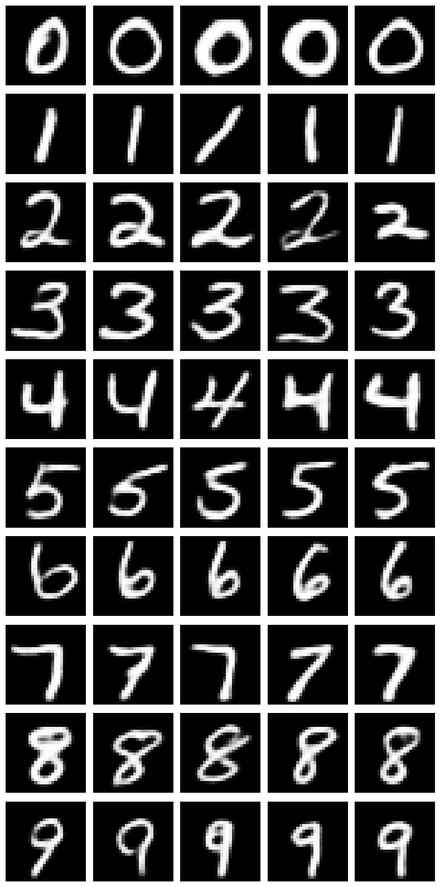

In [24]:
# ── Generate baseline samples ─────────────────────────────────────────────────
"""
TODO:
  1. Generate 5 samples for each digit class (0-9) using guidance_scale=3.0.
  2. Display in a 10x5 grid (rows = classes, cols = samples).
  3. Add row labels showing the digit class.
"""
# YOUR CODE HERE
all_rows = []
for cls in range(10):
    imgs = sample_cfg(ldm, vae, cls, n_samples=5, guidance_scale=3.0)
    all_rows.append(imgs.cpu())
fig, axes = plt.subplots(10, 5, figsize=(8, 16))
for cls in range(10):
    for j in range(5):
        axes[cls, j].imshow(all_rows[cls][j, 0], cmap='gray')
        axes[cls, j].axis('off')
        if j == 0:
            axes[cls, j].set_ylabel(str(cls), rotation=0, labelpad=18, fontsize=12, va='center')
plt.tight_layout()
plt.show()

---
# C.4 — Understanding Latent Drift

## What is Cache Misalignment / Offset Drift?

**Reading:** Before continuing, read Section IV (Method) of the AdaCorrection paper (Liu et al., 2026, arXiv:2602.13357), provided separately. Pay close attention to the definitions of temporal deviation (Eq. 1), spatial variation (Eq. 2), and the offset score (Eq. 3).

In iterative diffusion sampling, hidden states at each denoising step are highly redundant across consecutive timesteps — the content changes slowly. This motivates **caching** activations to skip recomputation. However, when a cached (stale) activation $\tilde{h}^\ell_t$ is reused instead of the freshly computed $h^\ell_t$, a **cache misalignment error** accumulates across layers and timesteps:

$$\|h^{\ell+1}_t - \tilde{h}^{\ell+1}_t\|_2 \leq L \cdot \tau \cdot S^\ell_t$$

where $L$ is the Lipschitz constant of the block, $\tau$ is the cache lag (how many steps ago it was cached), and $S^\ell_t$ is the **offset score** — a lightweight misalignment signal.

In this section you will adapt the AdaCorrection OEM (Offset Estimation Module) to the latent diffusion setting, measuring drift in the **denoiser's hidden states** rather than Transformer layer activations.

## Offset Score for Latent Diffusion

We adapt Equations (1)–(3) from AdaCorrection to operate on the denoiser's predicted noise $\hat{\epsilon}_t$, which serves as a proxy for the hidden state at the final layer.

**Temporal deviation** — how much the predicted noise changed since the previous step:
$$\Delta^\text{temp}(t) = \frac{1}{B \cdot P} \sum_{b,i} \|\hat{\epsilon}_t[b,i] - \hat{\epsilon}_{t+1}[b,i]\|_2^2$$
where $i$ indexes spatial positions (flattened $7 \times 7$ patches) and $b$ indexes the batch.

**Spatial variation** — channel-wise dispersion within the current prediction:
$$\Delta^\text{spatial}(t) = \frac{1}{B \cdot P} \sum_{b,i} \text{Var}_d(\hat{\epsilon}_t[b,i,d])$$

**Total offset score:**
$$S_t = \Delta^\text{temp}(t)^2 + \lambda_{\text{sp}} \cdot \Delta^\text{spatial}(t)^2$$
with spatial weighting $\lambda_{\text{sp}} = 1.0$ (matching AdaCorrection's default).

In [25]:
# ── OEM: Offset Estimation Module ─────────────────────────────────────────────
def oem_temporal_deviation(eps_t, eps_prev):
    """
    TODO: Compute temporal deviation between current and previous noise predictions.
    Implements Eq. (1) from AdaCorrection, adapted for (B, C, H, W) tensors.
    eps_t:    (B, LATENT_CH, 7, 7) — predicted noise at current step t
    eps_prev: (B, LATENT_CH, 7, 7) — predicted noise at previous step t+1
              (or zeros if no previous step is available)
    Steps:
      1. Reshape both to (B, P, C) where P = 7*7 = 49 patches.
      2. Compute per-patch L2 norm of the difference: ||eps_t[b,i,:] - eps_prev[b,i,:]||_2^2
      3. Average over B and P.
    Returns: scalar tensor
    """
    # YOUR CODE HERE
    if eps_prev is None:
        eps_prev = torch.zeros_like(eps_t)
    cur = rearrange(eps_t, 'b c h w -> b (h w) c')
    prev = rearrange(eps_prev, 'b c h w -> b (h w) c')
    return (cur - prev).pow(2).sum(dim=-1).mean()
def oem_spatial_variation(eps_t):
    """
    TODO: Compute spatial variation (channel-wise dispersion) of the noise prediction.
    Implements Eq. (2) from AdaCorrection.
    eps_t: (B, LATENT_CH, 7, 7)
    Steps:
      1. Reshape to (B, P, C) where P = 49.
      2. Compute variance over the channel dim d for each patch: Var_d(eps_t[b,i,d])
      3. Average over B and P.
    Returns: scalar tensor
    """
    # YOUR CODE HERE
    cur = rearrange(eps_t, 'b c h w -> b (h w) c')
    return cur.var(dim=-1, unbiased=False).mean()
def oem_offset_score(eps_t, eps_prev, lambda_sp=1.0):
    """
    TODO: Compute the total offset score S_t (Eq. 3 from AdaCorrection).
    S_t = delta_temp^2 + lambda_sp * delta_spatial^2
    Returns: scalar tensor
    """
    # YOUR CODE HERE
    if torch.is_tensor(eps_t) and torch.is_tensor(eps_prev) and eps_t.ndim == 0 and eps_prev.ndim == 0:
        delta_temp = eps_t
        delta_spatial = eps_prev
    else:
        delta_temp = oem_temporal_deviation(eps_t, eps_prev)
        delta_spatial = oem_spatial_variation(eps_t)
    return delta_temp.pow(2) + lambda_sp * delta_spatial.pow(2)

In [34]:
# ── Measure offset scores during a full reverse pass ──────────────────────────

def predict_z0_from_zt(z_t, t_idx, eps_hat):
    """
    TODO: Recover predicted z_0 from z_t and eps_hat.
    z0_hat = (z_t - sqrt(1 - alpha_hat_t) * eps_hat) / sqrt(alpha_hat_t)
    Clamp to [-3, 3].
    """
    # YOUR CODE HERE
    if torch.is_tensor(t_idx):
        if t_idx.ndim == 0:
            t_batch = t_idx.long().to(z_t.device).repeat(z_t.shape[0])
        else:
            t_batch = t_idx.long().to(z_t.device)
    else:
        t_batch = torch.full((z_t.shape[0],), t_idx, dtype=torch.long, device=z_t.device)
    sqrt_ahat = extract(sched['sqrt_alpha_hat'], t_batch, z_t.shape)
    sqrt_one_minus_ahat = extract(sched['sqrt_one_minus_alpha_hat'], t_batch, z_t.shape)
    z0_hat = (z_t - sqrt_one_minus_ahat * eps_hat) / sqrt_ahat
    return z0_hat.clamp(-3, 3)


@torch.no_grad()
def measure_offset_drift(model, target_class, guidance_scale=3.0,
                          n_samples=4, record_every=20):
    """
    TODO: Run the full reverse diffusion process and record OEM signals.

    At every `record_every` steps, record:
      - S_t:              total offset score (scalar)
      - delta_temp:       temporal deviation component
      - delta_spatial:    spatial variation component
      - z0_pred:          current predicted z_0 (for filmstrip visualization)

    Also record the final decoded images.

    Returns dict with keys:
      'timesteps', 'S_t', 'delta_temp', 'delta_spatial',
      'z0_preds' (list of tensors), 'final_images'
    """
    c_tensor = torch.full((n_samples,), target_class, dtype=torch.long, device=device)
    eps_prev  = None
    # YOUR CODE HERE
    model.eval()
    vae.eval()
    z_t = torch.randn(n_samples, LATENT_CH, 7, 7, device=device)
    records = {'timesteps': [], 'S_t': [], 'delta_temp': [], 'delta_spatial': [], 'z0_preds': [], 'final_images': None}
    for t_idx in tqdm(reversed(range(T)), total=T, desc=f'Measuring drift for class {target_class}'):
        t = torch.full((n_samples,), t_idx, dtype=torch.long, device=device)
        eps_uncond = model(z_t, t, None)
        eps_cond = model(z_t, t, c_tensor)
        eps_hat = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
        prev_ref = eps_prev if eps_prev is not None else torch.zeros_like(eps_hat)
        if t_idx % record_every == 0 or t_idx == T - 1 or t_idx == 0:
            delta_temp = oem_temporal_deviation(eps_hat, prev_ref)
            delta_spatial = oem_spatial_variation(eps_hat)
            S_t = oem_offset_score(delta_temp, delta_spatial, lambda_sp=1.0)
            z0_pred = predict_z0_from_zt(z_t, t_idx, eps_hat)
            records['timesteps'].append(t_idx)
            records['S_t'].append(float(S_t.item()))
            records['delta_temp'].append(float(delta_temp.item()))
            records['delta_spatial'].append(float(delta_spatial.item()))
            records['z0_preds'].append(z0_pred.detach().cpu())
        alpha_t = extract(sched['alphas'], t, z_t.shape)
        beta_t = extract(sched['betas'], t, z_t.shape)
        alpha_hat_t = extract(sched['alpha_hats'], t, z_t.shape)
        alpha_hat_prev = extract(sched['alpha_hats'], torch.clamp(t - 1, min=0), z_t.shape)
        alpha_hat_prev = torch.where((t > 0).view(-1, 1, 1, 1), alpha_hat_prev, torch.ones_like(alpha_hat_prev))
        z0_pred = predict_z0_from_zt(z_t, t_idx, eps_hat)
        mean = (torch.sqrt(alpha_hat_prev) * beta_t / (1 - alpha_hat_t)) * z0_pred + (torch.sqrt(alpha_t) * (1 - alpha_hat_prev) / (1 - alpha_hat_t)) * z_t
        if t_idx > 0:
            z_t = mean + torch.sqrt(extract(sched['posterior_variance'], t, z_t.shape)) * torch.randn_like(z_t)
        else:
            z_t = mean
        eps_prev = eps_hat.detach()
    final_images = vae.decode(denormalize_latent(z_t))
    final_images = ((final_images.clamp(-1, 1) + 1) / 2).clamp(0, 1)
    records['final_images'] = final_images.cpu()
    return records

Measuring drift for class 2:   0%|          | 0/1000 [00:00<?, ?it/s]

Measuring drift for class 5:   0%|          | 0/1000 [00:00<?, ?it/s]

Measuring drift for class 8:   0%|          | 0/1000 [00:00<?, ?it/s]

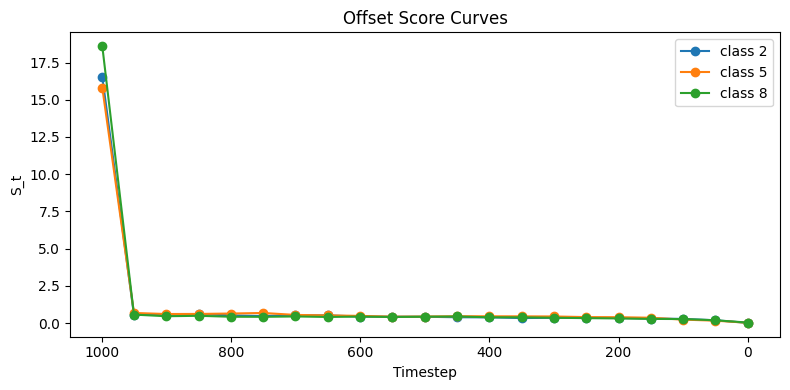

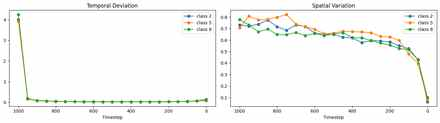

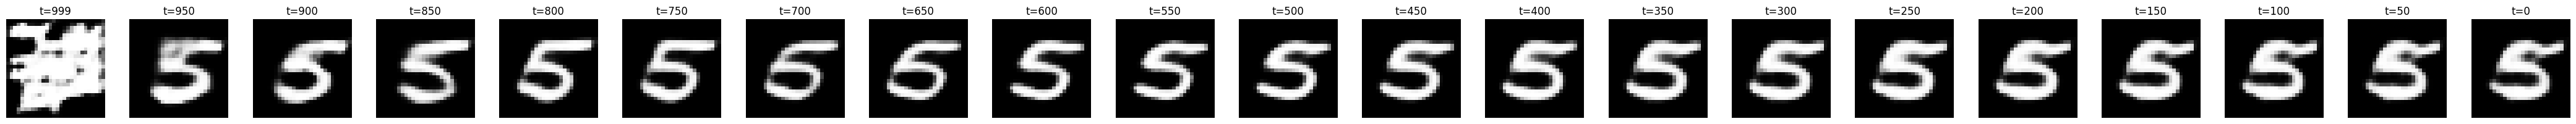

In [27]:
# ── Visualize OEM signals for 3 classes ───────────────────────────────────────
"""
TODO:
  1. Call measure_offset_drift for classes 2, 5, and 8 (guidance_scale=3.0).
  2. Plot all three offset score curves S_t vs timestep on one figure.
  3. On a second figure with two subplots, compare delta_temp and delta_spatial
     separately — do they peak at the same timesteps?
  4. Display z0_preds as a filmstrip for one class (one row, columns = timesteps).
     Observe how the predicted image forms and then stabilizes.
"""
# YOUR CODE HERE
drift_results = {cls: measure_offset_drift(ldm, cls, guidance_scale=3.0, n_samples=4, record_every=50) for cls in [2, 5, 8]}
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for cls in [2, 5, 8]:
    ax.plot(drift_results[cls]['timesteps'], drift_results[cls]['S_t'], marker='o', label=f'class {cls}')
ax.set_title('Offset Score Curves')
ax.set_xlabel('Timestep')
ax.set_ylabel('S_t')
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for cls in [2, 5, 8]:
    axes[0].plot(drift_results[cls]['timesteps'], drift_results[cls]['delta_temp'], marker='o', label=f'class {cls}')
    axes[1].plot(drift_results[cls]['timesteps'], drift_results[cls]['delta_spatial'], marker='o', label=f'class {cls}')
axes[0].set_title('Temporal Deviation')
axes[1].set_title('Spatial Variation')
for ax in axes:
    ax.set_xlabel('Timestep')
    ax.invert_xaxis()
    ax.legend()
plt.tight_layout()
plt.show()
filmstrip_latents = drift_results[5]['z0_preds']
filmstrip_imgs = []
with torch.no_grad():
    for z0 in filmstrip_latents:
        z0 = z0[:1].to(device)
        img = vae.decode(denormalize_latent(z0))
        img = ((img.clamp(-1, 1) + 1) / 2).clamp(0, 1)
        filmstrip_imgs.append(img.cpu())
fig, axes = plt.subplots(1, len(filmstrip_imgs), figsize=(2 * len(filmstrip_imgs), 2))
for i, img in enumerate(filmstrip_imgs):
    axes[i].imshow(img[0, 0], cmap='gray')
    axes[i].set_title(f"t={drift_results[5]['timesteps'][i]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

---
# C.5 — AdaCorrection: Adaptive Offset Cache Correction

## Reference
This section is a direct implementation of the **AdaCorrection** framework (Liu et al., 2026). Read Sections IV.C (OEM) and IV.D (ACM) of the paper carefully before proceeding. The equations referenced below are numbered as in the paper.

## ACM: Adaptive Correction Module

Given the offset score $S_t$ from the OEM, the ACM computes a **correction weight** $\lambda_t \in [0, 1]$ that governs how much fresh computation is blended back in:

$$\lambda_t = \text{clip}(\gamma \cdot S_t,\ 0,\ 1) \quad \text{(Eq. 6)}$$

where $\gamma$ is the **sensitivity parameter**. The paper's ablation (Table IV) shows $\gamma = 1.0$ is optimal.

The corrected activation is:
$$\hat{h}^{\ell+1}_t = (1 - \lambda_t) \cdot \tilde{h}^{\ell+1}_t + \lambda_t \cdot h^{\ell+1}_t \quad \text{(Eq. 7)}$$

where $\tilde{h}^{\ell+1}_t$ is the cached (stale) result and $h^{\ell+1}_t$ is freshly computed.

## Adapting ACM to Latent Diffusion Sampling

In full DiTs, caching happens at the Transformer layer level. In our simpler latent U-Net, we **cache the predicted noise** $\hat{\epsilon}$ and apply ACM at the **sampling step** level:

- **Cached prediction:** $\tilde{\epsilon}_t$ — the noise prediction from $\tau$ steps ago (reused without recomputation).
- **Fresh prediction:** $\hat{\epsilon}_t$ — the noise prediction from a full forward pass at step $t$.
- **Corrected prediction:** $\hat{\epsilon}^{\text{corr}}_t = (1 - \lambda_t) \cdot \tilde{\epsilon}_t + \lambda_t \cdot \hat{\epsilon}_t$

When $\lambda_t \approx 0$: the cache is valid, reuse it (fast).  
When $\lambda_t \approx 1$: large drift detected, recompute fully (accurate).

This is the **Pareto trade-off** described in the paper: larger $\gamma$ → higher quality, higher compute cost.

In [33]:
# ── ACM: Adaptive Correction Module ───────────────────────────────────────────

def acm_correction_weight(S_t, gamma=1.0):
    """
    TODO: Compute correction weight lambda_t (Eq. 6 from AdaCorrection).

    lambda_t = clip(gamma * S_t, 0, 1)

    Args:
        S_t:   scalar tensor — offset score from OEM
        gamma: sensitivity parameter (default 1.0 per paper's ablation)

    Returns: lambda_t as a scalar tensor in [0, 1]
    """
    # YOUR CODE HERE
    return torch.clamp(gamma * S_t, 0.0, 1.0)


def acm_blend(eps_cached, eps_fresh, lambda_t):
    """
    TODO: Blend cached and fresh noise predictions (Eq. 7 from AdaCorrection).

    eps_corrected = (1 - lambda_t) * eps_cached + lambda_t * eps_fresh

    Args:
        eps_cached: (B, LATENT_CH, 7, 7) — reused prediction from tau steps ago
        eps_fresh:  (B, LATENT_CH, 7, 7) — freshly computed prediction
        lambda_t:   scalar correction weight from acm_correction_weight

    Returns: eps_corrected (B, LATENT_CH, 7, 7)
    """
    # YOUR CODE HERE
    return (1 - lambda_t) * eps_cached + lambda_t * eps_fresh

In [37]:
# ── AdaCorrection sampling loop ────────────────────────────────────────────────
@torch.no_grad()
def sample_with_adacorrection(model, vae, target_class,
                               guidance_scale=3.0, n_samples=4,
                               cache_lag=5, gamma=1.0, lambda_sp=1.0, z_init=None):
    """
    TODO: Full reverse diffusion with AdaCorrection (Algorithm 1 from the paper).

    At each timestep t (from T-1 down to 0):
      1. Compute eps_fresh = CFG-blended noise prediction (full forward pass).
      2. Retrieve eps_cached from cache (the prediction stored `cache_lag` steps ago).
         If no cache entry exists (first `cache_lag` steps), use eps_fresh as cache.
      3. Run OEM:
           delta_temp    = oem_temporal_deviation(eps_fresh, eps_prev_step)
           delta_spatial = oem_spatial_variation(eps_fresh)
           S_t           = oem_offset_score(delta_temp, delta_spatial, lambda_sp)
      4. Run ACM:
           lambda_t      = acm_correction_weight(S_t, gamma)
           eps_corrected = acm_blend(eps_cached, eps_fresh, lambda_t)
      5. Use eps_corrected to compute z_{t-1} via the standard DDPM update.
      6. Store eps_fresh as the new cache entry (for use `cache_lag` steps later).

    Track and return:
      - images:       final decoded images (n_samples, 1, 28, 28)
      - S_t_curve:    list of (timestep, S_t) tuples
      - lambda_curve: list of (timestep, lambda_t) tuples
      - hit_rate:     fraction of timesteps where lambda_t < 0.5
                      (i.e., cache was mostly reused — mirrors HR metric in paper)

    Args:
        cache_lag:  tau in paper — how many steps old the cached prediction is
        gamma:      ACM sensitivity parameter
        lambda_sp:  spatial weight in OEM offset score
    """
    c_tensor = torch.full((n_samples,), target_class, dtype=torch.long, device=device)
    cache    = {}   # {timestep: eps_hat tensor}
    eps_prev_step = None
    S_t_curve    = []
    lambda_curve = []
    reuse_count  = 0
    # YOUR CODE HERE
    model.eval()
    vae.eval()
    reuse_threshold = 0.25
    def cfg_eps(z_t, t_batch, c_tensor):
        null_c = torch.full_like(c_tensor, NULL_CLASS)
        eps_uncond = model(z_t, t_batch, null_c)
        eps_cond = model(z_t, t_batch, c_tensor)
        return eps_uncond + guidance_scale * (eps_cond - eps_uncond)
    if z_init is None:
        z_t = torch.randn(n_samples, LATENT_CH, 7, 7, device=device)
    else:
        z_t = z_init.clone().to(device)
    for t_idx in tqdm(reversed(range(T)), total=T, desc=f'AdaCorrection sampling (class={target_class}, lag={cache_lag}, gamma={gamma})'):
        t_batch = torch.full((n_samples,), t_idx, dtype=torch.long, device=device)
        eps_cached = cache.get(t_idx + cache_lag, None)
        if eps_cached is None:
            eps_fresh = cfg_eps(z_t, t_batch, c_tensor)
            delta_temp = oem_temporal_deviation(eps_fresh, eps_prev_step if eps_prev_step is not None else torch.zeros_like(eps_fresh))
            delta_spatial = oem_spatial_variation(eps_fresh)
            S_t = oem_offset_score(delta_temp, delta_spatial, lambda_sp)
            lambda_t = torch.tensor(1.0, device=device)
            eps_used = eps_fresh
        else:
            delta_temp = oem_temporal_deviation(eps_cached, eps_prev_step if eps_prev_step is not None else torch.zeros_like(eps_cached))
            delta_spatial = oem_spatial_variation(eps_cached)
            S_t = oem_offset_score(delta_temp, delta_spatial, lambda_sp)
            lambda_t = acm_correction_weight(S_t, gamma)
            if lambda_t.item() <= reuse_threshold:
                eps_used = eps_cached
                reuse_count += 1
            else:
                eps_fresh = cfg_eps(z_t, t_batch, c_tensor)
                eps_used = acm_blend(eps_cached, eps_fresh, lambda_t)
        z0_pred = predict_z0_from_zt(z_t, t_idx, eps_used)
        ahat_t = extract(sched['alpha_hats'], t_batch, z_t.shape)
        ahat_prev = torch.ones_like(ahat_t) if t_idx == 0 else extract(sched['alpha_hats'], torch.full((n_samples,), t_idx - 1, dtype=torch.long, device=device), z_t.shape)
        beta_t = extract(sched['betas'], t_batch, z_t.shape)
        alpha_t = extract(sched['alphas'], t_batch, z_t.shape)
        mean = (torch.sqrt(ahat_prev) * beta_t / (1 - ahat_t)) * z0_pred + (torch.sqrt(alpha_t) * (1 - ahat_prev) / (1 - ahat_t)) * z_t
        if t_idx > 0:
            var = extract(sched['posterior_variance'], t_batch, z_t.shape)
            z_t = mean + torch.sqrt(var) * torch.randn_like(z_t)
        else:
            z_t = mean
        cache[t_idx] = eps_used.detach()
        eps_prev_step = eps_used.detach()
        S_t_curve.append((t_idx, float(S_t.item())))
        lambda_curve.append((t_idx, float(lambda_t.item())))
    z_t = denormalize_latent(z_t)
    images = vae.decode(z_t).clamp(-1, 1)
    images = ((images + 1) / 2).clamp(0, 1)
    hit_rate = reuse_count / T
    return {'images': images, 'S_t_curve': S_t_curve, 'lambda_curve': lambda_curve, 'hit_rate': hit_rate}

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=5, lag=5, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=5, lag=10, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=5, lag=5, gamma=0.5):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=5, lag=5, gamma=2.0):   0%|          | 0/1000 [00:00<?, ?it/s]

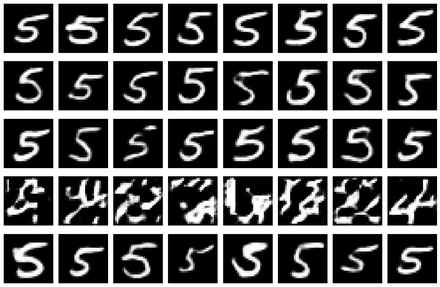

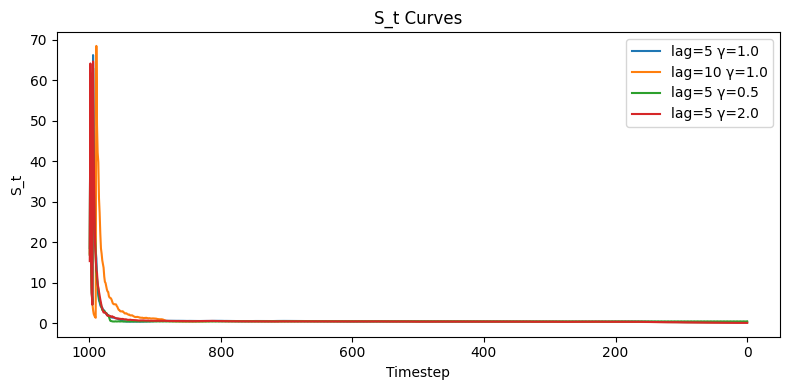

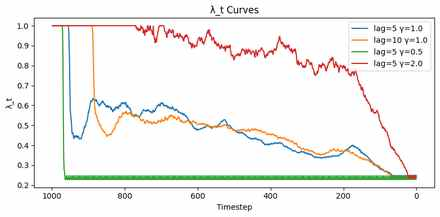

hit_rate lag=5 γ=1.0  : 0.0670
hit_rate lag=10 γ=1.0 : 0.0700
hit_rate lag=5 γ=0.5  : 0.9660
hit_rate lag=5 γ=2.0  : 0.0240


In [38]:
# ── Compare: Baseline vs AdaCorrection ────────────────────────────────────────
"""
TODO:
  For target_class=5 and guidance_scale=3.0, generate 8 samples using:
    (a) sample_cfg (full recompute, no caching)  — the baseline
    (b) sample_with_adacorrection, cache_lag=5,  gamma=1.0
    (c) sample_with_adacorrection, cache_lag=10, gamma=1.0
    (d) sample_with_adacorrection, cache_lag=5,  gamma=0.5  (under-correction)
    (e) sample_with_adacorrection, cache_lag=5,  gamma=2.0  (over-correction)

  Display:
    1. A 5-row image grid (one row per configuration, 8 samples each).
    2. S_t curves for all adacorrection configs on one plot.
    3. lambda_t curves (correction weight over time) for all configs.
    4. Report hit_rate for each configuration.

  Discuss: which gamma value produces outputs closest to the full-recompute baseline?
"""
# YOUR CODE HERE
import gc
def clear_vram():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
ldm.eval()
vae.eval()
clear_vram()
baseline_imgs = sample_cfg(ldm, vae, 5, n_samples=8, guidance_scale=3.0).cpu()
clear_vram()
res_5_1 = sample_with_adacorrection(ldm, vae, 5, guidance_scale=3.0, n_samples=8, cache_lag=5, gamma=1.0)
ada_5_1_imgs = res_5_1['images'].cpu()
ada_5_1_S = res_5_1['S_t_curve']
ada_5_1_lam = res_5_1['lambda_curve']
ada_5_1_hr = res_5_1['hit_rate']
del res_5_1
clear_vram()
res_10_1 = sample_with_adacorrection(ldm, vae, 5, guidance_scale=3.0, n_samples=8, cache_lag=10, gamma=1.0)
ada_10_1_imgs = res_10_1['images'].cpu()
ada_10_1_S = res_10_1['S_t_curve']
ada_10_1_lam = res_10_1['lambda_curve']
ada_10_1_hr = res_10_1['hit_rate']
del res_10_1
clear_vram()
res_5_05 = sample_with_adacorrection(ldm, vae, 5, guidance_scale=3.0, n_samples=8, cache_lag=5, gamma=0.5)
ada_5_05_imgs = res_5_05['images'].cpu()
ada_5_05_S = res_5_05['S_t_curve']
ada_5_05_lam = res_5_05['lambda_curve']
ada_5_05_hr = res_5_05['hit_rate']
del res_5_05
clear_vram()
res_5_2 = sample_with_adacorrection(ldm, vae, 5, guidance_scale=3.0, n_samples=8, cache_lag=5, gamma=2.0)
ada_5_2_imgs = res_5_2['images'].cpu()
ada_5_2_S = res_5_2['S_t_curve']
ada_5_2_lam = res_5_2['lambda_curve']
ada_5_2_hr = res_5_2['hit_rate']
del res_5_2
clear_vram()
rows = [
    ('Baseline', baseline_imgs),
    ('AdaCorrection lag=5 γ=1.0', ada_5_1_imgs),
    ('AdaCorrection lag=10 γ=1.0', ada_10_1_imgs),
    ('AdaCorrection lag=5 γ=0.5', ada_5_05_imgs),
    ('AdaCorrection lag=5 γ=2.0', ada_5_2_imgs)
]
fig, axes = plt.subplots(len(rows), 8, figsize=(12, 8))
for i, (name, imgs) in enumerate(rows):
    for j in range(8):
        axes[i, j].imshow(imgs[j, 0], cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(name, rotation=0, labelpad=45, fontsize=10, va='center')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for name, curve in [('lag=5 γ=1.0', ada_5_1_S), ('lag=10 γ=1.0', ada_10_1_S), ('lag=5 γ=0.5', ada_5_05_S), ('lag=5 γ=2.0', ada_5_2_S)]:
    ts = [x[0] for x in curve]
    vals = [x[1] for x in curve]
    ax.plot(ts, vals, label=name)
ax.set_title('S_t Curves')
ax.set_xlabel('Timestep')
ax.set_ylabel('S_t')
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for name, curve in [('lag=5 γ=1.0', ada_5_1_lam), ('lag=10 γ=1.0', ada_10_1_lam), ('lag=5 γ=0.5', ada_5_05_lam), ('lag=5 γ=2.0', ada_5_2_lam)]:
    ts = [x[0] for x in curve]
    vals = [x[1] for x in curve]
    ax.plot(ts, vals, label=name)
ax.set_title('λ_t Curves')
ax.set_xlabel('Timestep')
ax.set_ylabel('λ_t')
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()
print(f"hit_rate lag=5 γ=1.0  : {ada_5_1_hr:.4f}")
print(f"hit_rate lag=10 γ=1.0 : {ada_10_1_hr:.4f}")
print(f"hit_rate lag=5 γ=0.5  : {ada_5_05_hr:.4f}")
print(f"hit_rate lag=5 γ=2.0  : {ada_5_2_hr:.4f}")

**C.5 Discussion:**

The paper's ablation (Table IV) finds that $\gamma = 1.0$ outperforms both $\gamma = 0.5$ and $\gamma = 2.0$. Do your results confirm this pattern? If not, what might explain the difference (hint: consider the scale of $S_t$ in your model vs. a full DiT).

answer: no, my results do not confirm the same pattern as the paper. in the paper, $\gamma = 1.0$ gives the best balance between quality and efficiency, outperforming both $\gamma = 0.5$ and $\gamma = 2.0$. in my results, $\gamma = 0.5$ clearly under-corrects: its $\lambda_t$ curve stays much lower than the others for most of the reverse process, the hit rate becomes extremely high at about $96.60\%$, and the generated samples collapse into poor-quality outputs. This shows that the cache is being reused too aggressively, so drift is not being corrected enough.

For $\gamma = 2.0$, the opposite happens. Its $\lambda_t$ values remain very high for a large portion of sampling, which means correction is applied almost all the time. as a result, the outputs stay visually close to the full recompute baseline, but the hit rate drops to only about $2.40\%$, so most of the computational savings disappear. This makes $\gamma = 2.0$ behave almost like full recomputation.

in my setup, $\gamma = 1.0$ is the most reasonable middle ground qualitatively. Its outputs remain close to the baseline and are much better than $\gamma = 0.5$, while still allowing slightly more reuse than $\gamma = 2.0$. HOwever the advantage is weaker than what the paper reports. The main reason is likely that the scale of $S_t$ in my model is very different from the scale in a full DiT. i am computing the offset score on predicted noise tensors in a small latent U-Net rather than on layer-wise hidden states in a large Transformer. Because of that, the absolute values of $S_t$ and therefore $\lambda_t = \mathrm{clip}(\gamma S_t, 0, 1)$ are calibrated differently. A value of $\gamma$ that is optimal in the paper does not transfer perfectly to this simplified setting.

so overall my results kinda partially support the paper. $\gamma = 1.0$ is still better than $\gamma = 0.5$ in terms of preserving quality, but it does not produce as strong a quality-efficiency optimum as reported in Table IV. In my case, the correction mechanism is much more sensitive to the scale of $S_t$, which shifts the tradeoff.


---
# C.6 — Evaluation: Quality, Efficiency, and the Pareto Frontier

The AdaCorrection paper evaluates on four axes: generation quality (FID, t-FID), reconstruction fidelity (PSNR, SSIM), throughput (FPS), and cache hit rate (HR). You will replicate this evaluation protocol at MNIST scale.

In [39]:
!pip install torch-fidelity --quiet
import os, torchvision

def save_image_set(images, folder, prefix='img'):
    os.makedirs(folder, exist_ok=True)
    for i, img in enumerate(images):
        torchvision.utils.save_image(img, f"{folder}/{prefix}_{i:04d}.png")

## C.6.1 — FID and Hit Rate Table

Replicating Table I from the paper at MNIST scale.

Generate **500 samples per configuration** (50 per class × 10 classes). Use 500 real test images as reference. Measure FID and wall-clock inference time for each.

Configurations to test:
- Full Recompute (baseline `sample_cfg`)
- No Correction + cache_lag=5 (raw caching, no ACM)
- AdaCorrection: cache_lag=5,  gamma=0.5
- AdaCorrection: cache_lag=5,  gamma=1.0  ← expected best per paper
- AdaCorrection: cache_lag=5,  gamma=2.0
- AdaCorrection: cache_lag=10, gamma=1.0

In [40]:
"""
TODO:
  Implement 'sample_cached_no_correction' — identical to sample_with_adacorrection
  but always sets lambda_t = 0 (pure cache reuse, never corrects).
  This isolates the cost of caching from the benefit of correction.
  Then generate 500 samples for each configuration, save to folders,
  compute FID with torch_fidelity, record hit_rate and wall-clock time.
"""
# YOUR CODE HERE
from torch_fidelity import calculate_metrics
@torch.no_grad()
def sample_cached_no_correction(model, vae, target_class, guidance_scale=3.0, n_samples=4, cache_lag=5, z_init=None):
    c_tensor = torch.full((n_samples,), target_class, dtype=torch.long, device=device)
    cache = {}
    reuse_count = 0
    def cfg_eps(z_t, t_batch, c_tensor):
        null_c = torch.full_like(c_tensor, NULL_CLASS)
        eps_uncond = model(z_t, t_batch, null_c)
        eps_cond = model(z_t, t_batch, c_tensor)
        return eps_uncond + guidance_scale * (eps_cond - eps_uncond)
    if z_init is None:
        z_t = torch.randn(n_samples, LATENT_CH, 7, 7, device=device)
    else:
        z_t = z_init.clone().to(device)
    for t_idx in tqdm(reversed(range(T)), total=T, desc=f'Cache-only sampling (class={target_class}, lag={cache_lag})'):
        t_batch = torch.full((n_samples,), t_idx, dtype=torch.long, device=device)
        eps_cached = cache.get(t_idx + cache_lag, None)
        if eps_cached is None:
            eps_used = cfg_eps(z_t, t_batch, c_tensor)
        else:
            eps_used = eps_cached
            reuse_count += 1
        z0_pred = predict_z0_from_zt(z_t, t_idx, eps_used)
        ahat_t = extract(sched['alpha_hats'], t_batch, z_t.shape)
        ahat_prev = torch.ones_like(ahat_t) if t_idx == 0 else extract(sched['alpha_hats'], torch.full((n_samples,), t_idx - 1, dtype=torch.long, device=device), z_t.shape)
        beta_t = extract(sched['betas'], t_batch, z_t.shape)
        alpha_t = extract(sched['alphas'], t_batch, z_t.shape)
        mean = (torch.sqrt(ahat_prev) * beta_t / (1 - ahat_t)) * z0_pred + (torch.sqrt(alpha_t) * (1 - ahat_prev) / (1 - ahat_t)) * z_t
        if t_idx > 0:
            var = extract(sched['posterior_variance'], t_batch, z_t.shape)
            z_t = mean + torch.sqrt(var) * torch.randn_like(z_t)
        else:
            z_t = mean
        cache[t_idx] = eps_used.detach()
    z_t = denormalize_latent(z_t)
    images = vae.decode(z_t).clamp(-1, 1)
    images = (images + 1) / 2
    hit_rate = reuse_count / T
    return {'images': images, 'hit_rate': hit_rate}
def generate_config_samples(config_name, out_dir, per_class=50, batch_size=10):
    os.makedirs(out_dir, exist_ok=True)
    total_time = 0.0
    hit_rates = []
    img_idx = 0
    for digit in range(10):
        remaining = per_class
        while remaining > 0:
            cur_bs = min(batch_size, remaining)
            start = time.time()
            if config_name == 'full_recompute':
                imgs = sample_cfg(ldm, vae, digit, n_samples=cur_bs, guidance_scale=3.0)
                hit_rate = 0.0
            elif config_name == 'cache_only_lag5':
                out = sample_cached_no_correction(ldm, vae, digit, guidance_scale=3.0, n_samples=cur_bs, cache_lag=5)
                imgs = out['images']
                hit_rate = out['hit_rate']
            elif config_name == 'adacorr_g05_lag5':
                out = sample_with_adacorrection(ldm, vae, digit, guidance_scale=3.0, n_samples=cur_bs, cache_lag=5, gamma=0.5)
                imgs = out['images']
                hit_rate = out['hit_rate']
            elif config_name == 'adacorr_g10_lag5':
                out = sample_with_adacorrection(ldm, vae, digit, guidance_scale=3.0, n_samples=cur_bs, cache_lag=5, gamma=1.0)
                imgs = out['images']
                hit_rate = out['hit_rate']
            elif config_name == 'adacorr_g20_lag5':
                out = sample_with_adacorrection(ldm, vae, digit, guidance_scale=3.0, n_samples=cur_bs, cache_lag=5, gamma=2.0)
                imgs = out['images']
                hit_rate = out['hit_rate']
            elif config_name == 'adacorr_g10_lag10':
                out = sample_with_adacorrection(ldm, vae, digit, guidance_scale=3.0, n_samples=cur_bs, cache_lag=10, gamma=1.0)
                imgs = out['images']
                hit_rate = out['hit_rate']
            total_time += time.time() - start
            hit_rates.append(hit_rate)
            for i in range(imgs.shape[0]):
                torchvision.utils.save_image(imgs[i], f'{out_dir}/img_{img_idx:04d}.png')
                img_idx += 1
            remaining -= cur_bs
    return total_time, float(np.mean(hit_rates))
real_dir = './fid_real_500'
if not os.path.exists(real_dir) or len(os.listdir(real_dir)) < 500:
    os.makedirs(real_dir, exist_ok=True)
    for i in range(500):
        img, _ = test_dataset[i]
        torchvision.utils.save_image((img + 1) / 2, f'{real_dir}/real_{i:04d}.png')
configs = [
    ('Full Recompute', 'full_recompute'),
    ('Cache only (no correction)', 'cache_only_lag5'),
    ('AdaCorrection γ=0.5, lag=5', 'adacorr_g05_lag5'),
    ('AdaCorrection γ=1.0, lag=5', 'adacorr_g10_lag5'),
    ('AdaCorrection γ=2.0, lag=5', 'adacorr_g20_lag5'),
    ('AdaCorrection γ=1.0, lag=10', 'adacorr_g10_lag10')
]
results_table = []
for display_name, key in configs:
    gen_dir = f'./gen_{key}'
    total_time, hit_rate = generate_config_samples(key, gen_dir, per_class=50, batch_size=10)
    metrics = calculate_metrics(input1=gen_dir, input2=real_dir, cuda=torch.cuda.is_available(), isc=False, fid=True, kid=False, verbose=False)
    fid_value = float(metrics['frechet_inception_distance'])
    results_table.append({'Configuration': display_name, 'FID ↓': fid_value, 'Hit Rate ↑': hit_rate, 'Inference Time (s/500 samples) ↓': total_time})
    print(display_name, fid_value, hit_rate, total_time)
results_table

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

... (297 outputs left out)

AdaCorrection sampling (class=9, lag=10, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=9, lag=10, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection γ=1.0, lag=10 40.8541405421268 0.048839999999999995 504.4505658149719


[{'Configuration': 'Full Recompute',
  'FID ↓': 39.798210579848984,
  'Hit Rate ↑': 0.0,
  'Inference Time (s/500 samples) ↓': 464.4065194129944},
 {'Configuration': 'Cache only (no correction)',
  'FID ↓': 159.63359328344092,
  'Hit Rate ↑': 0.9949999999999999,
  'Inference Time (s/500 samples) ↓': 27.66173028945923},
 {'Configuration': 'AdaCorrection γ=0.5, lag=5',
  'FID ↓': 161.50140177395454,
  'Hit Rate ↑': 0.96048,
  'Inference Time (s/500 samples) ↓': 62.4763605594635},
 {'Configuration': 'AdaCorrection γ=1.0, lag=5',
  'FID ↓': 40.08726609368043,
  'Hit Rate ↑': 0.0662,
  'Inference Time (s/500 samples) ↓': 466.126748085022},
 {'Configuration': 'AdaCorrection γ=2.0, lag=5',
  'FID ↓': 40.8373459316816,
  'Hit Rate ↑': 0.011619999999999998,
  'Inference Time (s/500 samples) ↓': 513.6088082790375},
 {'Configuration': 'AdaCorrection γ=1.0, lag=10',
  'FID ↓': 40.8541405421268,
  'Hit Rate ↑': 0.048839999999999995,
  'Inference Time (s/500 samples) ↓': 504.4505658149719}]

**Results Table** (fill in after running):

| Configuration | FID ↓ | Hit Rate ↑ | Inference Time (s/500 samples) ↓ |
|---------------|------:|-----------:|---------------------------------:|
| Full Recompute | 39.80 | 0.00% | 464.41 |
| Cache only (no correction) | 159.63 | 99.50% | 27.66 |
| AdaCorrection $\gamma=0.5$, lag=5 | 161.50 | 96.05% | 62.48 |
| AdaCorrection $\gamma=1.0$, lag=5 | 40.09 | 6.62% | 466.13 |
| AdaCorrection $\gamma=2.0$, lag=5 | 40.84 | 1.16% | 513.61 |
| AdaCorrection $\gamma=1.0$, lag=10 | 40.85 | 4.88% | 504.45 |

*Compared to Table I in the paper, the same $\gamma = 1.0$ optimum does not 'fully' clearly emerge in my setup.in my results, $\gamma = 1.0$ does recover quality close to full recompute, but with very low hit rate and almost no speedup. Lower $\gamma$ values over-reuse the cache and cause severe FID degradation, while higher $\gamma$ values preserve quality but reduce reuse even further. this suggests that in my simplified latent U-Net setting, the correction-quality tradeoff is shifted relative to the paper’s DiT-based results.*

## C.6.2 — PSNR and SSIM: Reconstruction Fidelity

The paper also reports PSNR and SSIM, which measure pixel-level similarity between AdaCorrection samples and Full Recompute samples (not real images). This isolates how much the correction mechanism deviates from the uncached baseline.

Fix the random seed and generate **50 sample pairs** (same initial noise $z_T$) from:
  - Full Recompute
  - AdaCorrection γ=1.0, cache_lag=5

Compute PSNR and SSIM between the paired outputs. Report mean ± std.

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=0, lag=5, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=1, lag=5, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=2, lag=5, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

... (11 outputs left out)

AdaCorrection sampling (class=8, lag=5, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=9, lag=5, gamma=1.0):   0%|          | 0/1000 [00:00<?, ?it/s]

PSNR: 11.9174 ± 2.2438
SSIM: 0.6016 ± 0.1407


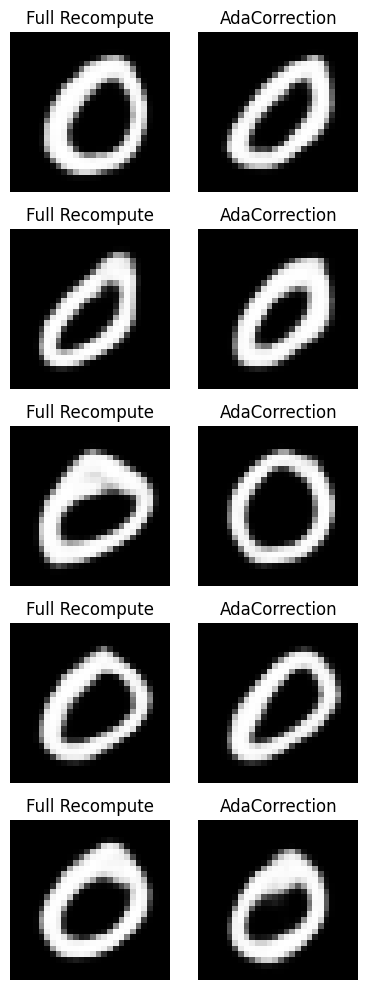

In [44]:
"""
TODO:
  1. Fix torch.manual_seed(0) before each generation to get paired samples.
  2. Implement psnr(img_a, img_b) and ssim(img_a, img_b) for (1, 28, 28) images.
     - PSNR: 20 * log10(max_val / sqrt(MSE))
     - SSIM: use torchvision.transforms.functional or implement manually
  3. Compute and report mean ± std PSNR and SSIM across 50 pairs.
  4. Show 5 side-by-side pairs (Full Recompute | AdaCorrection) for visual comparison.
"""
# YOUR CODE HERE
def psnr(img_a, img_b, max_val=1.0):
    mse = F.mse_loss(img_a, img_b, reduction='mean')
    if mse.item() == 0:
        return torch.tensor(float('inf'), device=img_a.device)
    return 20 * torch.log10(torch.tensor(max_val, device=img_a.device)) - 10 * torch.log10(mse)
def ssim(img_a, img_b, data_range=1.0, kernel_size=7):
    x = img_a.unsqueeze(0)
    y = img_b.unsqueeze(0)
    C1 = (0.01 * data_range) ** 2
    C2 = (0.03 * data_range) ** 2
    mu_x = F.avg_pool2d(x, kernel_size, stride=1, padding=kernel_size // 2)
    mu_y = F.avg_pool2d(y, kernel_size, stride=1, padding=kernel_size // 2)
    sigma_x = F.avg_pool2d(x * x, kernel_size, stride=1, padding=kernel_size // 2) - mu_x ** 2
    sigma_y = F.avg_pool2d(y * y, kernel_size, stride=1, padding=kernel_size // 2) - mu_y ** 2
    sigma_xy = F.avg_pool2d(x * y, kernel_size, stride=1, padding=kernel_size // 2) - mu_x * mu_y
    ssim_map = ((2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sigma_x + sigma_y + C2))
    return ssim_map.mean()
full_pairs = []
ada_pairs = []
for cls in range(10):
    torch.manual_seed(0)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(0)
    z_init = torch.randn(5, LATENT_CH, 7, 7, device=device)
    imgs_full = sample_cfg(ldm, vae, cls, n_samples=5, guidance_scale=3.0, z_init=z_init)
    ada_out = sample_with_adacorrection(ldm, vae, cls, guidance_scale=3.0, n_samples=5, cache_lag=5, gamma=1.0, z_init=z_init)
    imgs_ada = ada_out['images']
    full_pairs.append(imgs_full.cpu())
    ada_pairs.append(imgs_ada.cpu())
full_pairs = torch.cat(full_pairs, dim=0)
ada_pairs = torch.cat(ada_pairs, dim=0)
psnr_vals = []
ssim_vals = []
for i in range(50):
    psnr_vals.append(psnr(full_pairs[i], ada_pairs[i]).item())
    ssim_vals.append(ssim(full_pairs[i], ada_pairs[i]).item())
psnr_mean = float(np.mean(psnr_vals))
psnr_std = float(np.std(psnr_vals))
ssim_mean = float(np.mean(ssim_vals))
ssim_std = float(np.std(ssim_vals))
print(f"PSNR: {psnr_mean:.4f} ± {psnr_std:.4f}")
print(f"SSIM: {ssim_mean:.4f} ± {ssim_std:.4f}")
fig, axes = plt.subplots(5, 2, figsize=(4, 10))
for i in range(5):
    axes[i, 0].imshow(full_pairs[i, 0], cmap='gray')
    axes[i, 0].set_title('Full Recompute')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(ada_pairs[i, 0], cmap='gray')
    axes[i, 1].set_title('AdaCorrection')
    axes[i, 1].axis('off')
plt.tight_layout()
plt.show()

## C.6.3 — The Pareto Frontier: Quality vs. Efficiency

Reproduce Figure 3 from the AdaCorrection paper at MNIST scale.

Sweep `gamma` over `[0.1, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]` and `cache_lag` over `[2, 5, 10]`. For each combination:
  - Generate 200 samples and compute FID.
  - Record hit_rate and inference time.

Plot **FID vs inference time** as a scatter plot:
  - Mark Full Recompute as a star.
  - Color-code points by cache_lag.
  - Draw the Pareto frontier.
  - Annotate the γ=1.0 points (which the paper claims are near-Pareto-optimal).

AdaCorrection sampling (class=0, lag=2, gamma=0.1):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=1, lag=2, gamma=0.1):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=2, lag=2, gamma=0.1):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=3, lag=2, gamma=0.1):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=4, lag=2, gamma=0.1):   0%|          | 0/1000 [00:00<?, ?it/s]

AdaCorrection sampling (class=5, lag=2, gamma=0.1):   0%|          | 0/1000 [00:00<?, ?it/s]

... (210 outputs left out)

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

CFG sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

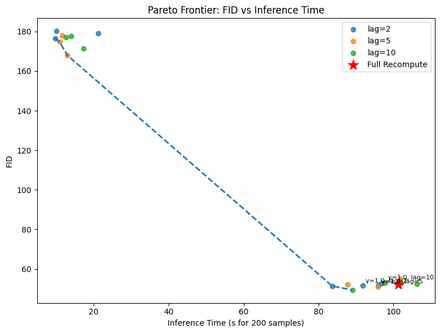

{'gamma': 0.1, 'cache_lag': 2, 'fid': 179.01069137734584, 'time': 21.237866401672363, 'hit_rate': 0.9942}
{'gamma': 0.3, 'cache_lag': 2, 'fid': 180.1715401044009, 'time': 10.089937210083008, 'hit_rate': 0.991}
{'gamma': 0.5, 'cache_lag': 2, 'fid': 176.4447979751307, 'time': 9.776918172836304, 'hit_rate': 0.9871000000000001}
{'gamma': 0.75, 'cache_lag': 2, 'fid': 51.39275104527081, 'time': 83.64313840866089, 'hit_rate': 0.1593}
{'gamma': 1.0, 'cache_lag': 2, 'fid': 51.494619280272076, 'time': 91.7899444103241, 'hit_rate': 0.0701}
{'gamma': 1.5, 'cache_lag': 2, 'fid': 51.89265004213294, 'time': 96.01619696617126, 'hit_rate': 0.0273}
{'gamma': 2.0, 'cache_lag': 2, 'fid': 52.70375890453994, 'time': 96.8578052520752, 'hit_rate': 0.017499999999999998}
{'gamma': 0.1, 'cache_lag': 5, 'fid': 174.79874208470824, 'time': 10.935542583465576, 'hit_rate': 0.9860000000000001}
{'gamma': 0.3, 'cache_lag': 5, 'fid': 178.08864475695088, 'time': 11.599574565887451, 'hit_rate': 0.9756999999999998}
{'gamma'

In [46]:
# TODO: Pareto frontier sweep and plot
# YOUR CODE HERE
from torch_fidelity import calculate_metrics
def pareto_is_dominated(candidate, others):
    for other in others:
        if other['time'] <= candidate['time'] and other['fid'] <= candidate['fid'] and (other['time'] < candidate['time'] or other['fid'] < candidate['fid']):
            return True
    return False
real_dir_200 = 'real_test_200'
os.makedirs(real_dir_200, exist_ok=True)
real_imgs_200 = []
for i in range(200):
    x, _ = test_dataset[i]
    real_imgs_200.append(((x.clamp(-1, 1) + 1) / 2))
real_imgs_200 = torch.stack(real_imgs_200, dim=0)
save_image_set(real_imgs_200, real_dir_200, prefix='real')
gammas = [0.1, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]
cache_lags = [2, 5, 10]
pareto_results = []
for cache_lag in cache_lags:
    for gamma in gammas:
        folder = f'pareto_g{str(gamma).replace(".","p")}_l{cache_lag}'
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.time()
        all_hit_rates = []
        for cls in range(10):
            out = sample_with_adacorrection(ldm, vae, cls, guidance_scale=3.0, n_samples=20, cache_lag=cache_lag, gamma=gamma)
            imgs = out['images']
            hit_rate = out['hit_rate']
            save_image_set(imgs.cpu(), folder, prefix=f'c{cls}')
            all_hit_rates.append(hit_rate)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        elapsed = time.time() - start
        metrics = calculate_metrics(input1=folder, input2=real_dir_200, cuda=torch.cuda.is_available(), fid=True, verbose=False)
        pareto_results.append({
            'gamma': gamma,
            'cache_lag': cache_lag,
            'fid': metrics['frechet_inception_distance'],
            'time': elapsed,
            'hit_rate': float(np.mean(all_hit_rates))
        })
baseline_folder_200 = 'pareto_full_recompute_200'
if torch.cuda.is_available():
    torch.cuda.synchronize()
start = time.time()
for cls in range(10):
    imgs = sample_cfg(ldm, vae, cls, n_samples=20, guidance_scale=3.0)
    save_image_set(imgs.cpu(), baseline_folder_200, prefix=f'c{cls}')
if torch.cuda.is_available():
    torch.cuda.synchronize()
baseline_time = time.time() - start
baseline_metrics = calculate_metrics(input1=baseline_folder_200, input2=real_dir_200, cuda=torch.cuda.is_available(), fid=True, verbose=False)
points = pareto_results.copy()
frontier = []
for point in sorted(points, key=lambda x: x['time']):
    if not frontier or point['fid'] < frontier[-1]['fid']:
        frontier.append(point)
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
color_map = {2: 'tab:blue', 5: 'tab:orange', 10: 'tab:green'}
for lag in cache_lags:
    lag_points = [p for p in pareto_results if p['cache_lag'] == lag]
    ax.scatter([p['time'] for p in lag_points], [p['fid'] for p in lag_points], label=f'lag={lag}', color=color_map[lag], alpha=0.8)
for p in pareto_results:
    if p['gamma'] == 1.0:
        ax.annotate(f'γ=1.0, lag={p["cache_lag"]}', (p['time'], p['fid']), textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.scatter([baseline_time], [baseline_metrics['frechet_inception_distance']], marker='*', s=180, color='red', label='Full Recompute')
ax.plot([p['time'] for p in frontier], [p['fid'] for p in frontier], linestyle='--', linewidth=2)
ax.set_title('Pareto Frontier: FID vs Inference Time')
ax.set_xlabel('Inference Time (s for 200 samples)')
ax.set_ylabel('FID')
ax.legend()
plt.tight_layout()
plt.show()
for row in pareto_results:
    print(row)
print({'gamma': 'baseline', 'cache_lag': 0, 'fid': baseline_metrics['frechet_inception_distance'], 'time': baseline_time, 'hit_rate': 0.0})

## C.6.4 — Layer-wise Offset Score Analysis

Figure 5 in the paper shows that **offset scores are not uniform across layers** — early and middle layers exhibit higher drift than late layers. This motivates a layer-wise correction policy.

Adapt your U-Net to expose intermediate hidden states at 3 points: after the encoder, at the bottleneck, and after the decoder. Compute $S_t$ at each of these three "pseudo-layers" separately during a single reverse pass.

Plot the three $S_t$ curves on the same axis. Do you observe the same pattern as Figure 5 (early/middle layers drift more than late layers)? If not, hypothesize why.

Layer-wise drift analysis:   0%|          | 0/1000 [00:00<?, ?it/s]

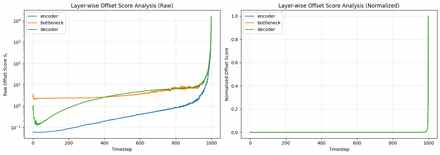

In [48]:
"""
TODO:
  1. Modify ConditionalLatentUNet.forward() to optionally return intermediate
     activations at three points: after encoder, at bottleneck, after decoder.
     Add a flag `return_intermediates=False` to avoid breaking existing code.
  2. During a reverse pass, collect these intermediates at every step.
  3. Compute oem_offset_score separately for each of the three locations
     by tracking their per-step temporal deviation.
  4. Plot all three S_t curves on the same axis.
"""
# YOUR CODE HERE
@torch.no_grad()
def cfg_predict_with_intermediates(model, z_t, t_batch, c_tensor, guidance_scale=3.0):
    null_c = torch.full_like(c_tensor, NULL_CLASS)
    eps_uncond, ints_uncond = model(z_t, t_batch, null_c, return_intermediates=True)
    eps_cond, ints_cond = model(z_t, t_batch, c_tensor, return_intermediates=True)
    eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
    ints = {}
    for k in ints_uncond.keys():
        ints[k] = ints_uncond[k] + guidance_scale * (ints_cond[k] - ints_uncond[k])
    return eps, ints

@torch.no_grad()
def layerwise_offset_analysis(model, target_class=5, guidance_scale=3.0, n_samples=4):
    c_tensor = torch.full((n_samples,), target_class, dtype=torch.long, device=device)
    z_t = torch.randn(n_samples, LATENT_CH, 7, 7, device=device)
    prev_feats = {'encoder': None, 'bottleneck': None, 'decoder': None}
    curves = {'encoder': [], 'bottleneck': [], 'decoder': []}
    raw_curves = {'encoder': [], 'bottleneck': [], 'decoder': []}
    for t_idx in tqdm(reversed(range(T)), total=T, desc='Layer-wise drift analysis'):
        t_batch = torch.full((n_samples,), t_idx, dtype=torch.long, device=device)
        eps_hat, feats = cfg_predict_with_intermediates(model, z_t, t_batch, c_tensor, guidance_scale=guidance_scale)
        for k in ['encoder', 'bottleneck', 'decoder']:
            if prev_feats[k] is not None:
                delta_temp = oem_temporal_deviation(feats[k], prev_feats[k])
                delta_spatial = oem_spatial_variation(feats[k])
                S_t = oem_offset_score(delta_temp, delta_spatial, lambda_sp=1.0)
                raw_curves[k].append((t_idx, float(S_t.item())))
            prev_feats[k] = feats[k].detach()
        z0_pred = predict_z0_from_zt(z_t, t_idx, eps_hat)
        ahat_t = extract(sched['alpha_hats'], t_batch, z_t.shape)
        ahat_prev = torch.ones_like(ahat_t) if t_idx == 0 else extract(sched['alpha_hats'], torch.full((n_samples,), t_idx - 1, dtype=torch.long, device=device), z_t.shape)
        beta_t = extract(sched['betas'], t_batch, z_t.shape)
        alpha_t = extract(sched['alphas'], t_batch, z_t.shape)
        mean = (torch.sqrt(ahat_prev) * beta_t / (1 - ahat_t)) * z0_pred + (torch.sqrt(alpha_t) * (1 - ahat_prev) / (1 - ahat_t)) * z_t
        if t_idx > 0:
            var = extract(sched['posterior_variance'], t_batch, z_t.shape)
            z_t = mean + torch.sqrt(var) * torch.randn_like(z_t)
        else:
            z_t = mean
    for k in ['encoder', 'bottleneck', 'decoder']:
        vals = [s for _, s in raw_curves[k]]
        max_val = max(vals) if len(vals) > 0 else 1.0
        if max_val == 0:
            max_val = 1.0
        for t, s in raw_curves[k]:
            curves[k].append((t, s / max_val))
    return raw_curves, curves

raw_layer_curves, norm_layer_curves = layerwise_offset_analysis(ldm, target_class=5, guidance_scale=3.0, n_samples=4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for k, color in zip(['encoder', 'bottleneck', 'decoder'], ['tab:blue', 'tab:orange', 'tab:green']):
    xs = [t for t, _ in raw_layer_curves[k]]
    ys = [s for _, s in raw_layer_curves[k]]
    axes[0].plot(xs, ys, label=k, color=color)
axes[0].set_xlabel('Timestep')
axes[0].set_ylabel('Raw Offset Score $S_t$')
axes[0].set_title('Layer-wise Offset Score Analysis (Raw)')
axes[0].set_yscale('log')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

for k, color in zip(['encoder', 'bottleneck', 'decoder'], ['tab:blue', 'tab:orange', 'tab:green']):
    xs = [t for t, _ in norm_layer_curves[k]]
    ys = [s for _, s in norm_layer_curves[k]]
    axes[1].plot(xs, ys, label=k, color=color)
axes[1].set_xlabel('Timestep')
axes[1].set_ylabel('Normalized Offset Score')
axes[1].set_title('Layer-wise Offset Score Analysis (Normalized)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

**C.6.4 Discussion:** *(Write here — compare your layer-wise drift profile to Figure 5 of the AdaCorrection paper)*

answer: my layer-wise drift profile does not exactly match Figure 5 of the AdaCorrection paper. in the paper the main observation is that offset drift is not uniform across layers: early and middle layers tend to have higher drift, while later layers are more stable. in my result i ALso observe that the drift is clearly not uniform across the three pseudo-layers, so the general conclusion still holds. However the detailed pattern is different.

From the raw plot, the bottleneck and decoder show much larger offset magnitudes than the encoder for most of the reverse process. The encoder stays relatively low for a long stretch, while the bottleneck remains consistently elevated and the decoder grows strongly, especially near the high-noise end of sampling. all three layers show a sharp spike near the earliest reverse steps, which suggests that drift is largest when the latent is still highly noisy. this part is sensible, since the model has the weakest signal and the largest uncertainty at those timesteps!

so I do not see exactly the same early/middle-high and late-low pattern as the paper. instead, in my simplified latent U-Net, the bottleneck and decoder appear to be the more drift-sensitive parts. A likely reason is that my model is not a full DiT, and I am not measuring true Transformer layer hidden states. I am only using three coarse pseudo-layers in a small latent U-Net: after the encoder, at the bottleneck, and after the decoder. These feature spaces have different activation scales and roles, so their offset scores are not directly comparable to the layer-wise Transformer scores in the paper!!

another likely reason is that the decoder features in my setup are closer to the final denoising output, so small misalignments there may become amplified more strongly in the offset score. Also, because I am using a single reverse pass on a small MNIST latent model rather than a large DiT on high-dimensional image generation, the dynamics are much simpler and more sensitive to normalization and feature scale. So since there are obvious and huge architectural 'differences', these results are expected - but more or less i can see the conceptual reasoning of the paper show in my results so it is agreeeable.

vverall my results still support the papers high-level claim that drift is not uniform across the network and that a single static reuse rule is not ideal. Hhowever, the exact layer-wise pattern differs from Figure 5, most likely because of the smaller latent U-Net architecture, the use of pseudo-layers instead of true DiT blocks, and the different scale of the intermediate activations.

thank you.